*  DSC540-T303 Data Preparation (2265-1)
*  Milestone 5
*  David Jorgensen

# Milestone 5

## Previous Work

### Milestones 1-2

In [267]:
# Load Libraries
import pandas as pd
import re

In [268]:
# Load data
flat_df = pd.read_csv('./broadway.csv')
# Display the first 10 rows of the dataset
flat_df.head(10)

,Date.Day,Date.Full,Date.Month,Date.Year,Show.Name,Show.Theatre,Show.Type,Statistics.Attendance,Statistics.Capacity,Statistics.Gross,Statistics.Gross Potential,Statistics.Performances
0,26,8/26/1990,8,1990,Tru,Booth,Play,5500,88,134456,0,8
1,24,3/24/1991,3,1991,Miss Saigon,Broadway,Musical,1737,100,100647,0,0
2,31,3/31/1991,3,1991,Miss Saigon,Broadway,Musical,12160,100,634424,0,0
3,7,4/7/1991,4,1991,Miss Saigon,Broadway,Musical,13921,100,713353,0,0
4,14,4/14/1991,4,1991,Miss Saigon,Broadway,Musical,10973,90,573981,0,4
5,21,4/21/1991,4,1991,Miss Saigon,Broadway,Musical,14076,101,706793,0,8
6,28,4/28/1991,4,1991,Miss Saigon,Broadway,Musical,14065,101,714968,0,8
7,5,5/5/1991,5,1991,Miss Saigon,Broadway,Musical,14064,101,730765,0,8
8,12,5/12/1991,5,1991,Miss Saigon,Broadway,Musical,13896,100,766713,0,8
9,19,5/19/1991,5,1991,Miss Saigon,Broadway,Musical,13738,99,763332,0,8


In [269]:
# Step 1: Filter to keep only rows where Show.Type is "Musical"
flat_df = flat_df[flat_df['Show.Type'] == 'Musical']
flat_df.head(10)

,Date.Day,Date.Full,Date.Month,Date.Year,Show.Name,Show.Theatre,Show.Type,Statistics.Attendance,Statistics.Capacity,Statistics.Gross,Statistics.Gross Potential,Statistics.Performances
1,24,3/24/1991,3,1991,Miss Saigon,Broadway,Musical,1737,100,100647,0,0
2,31,3/31/1991,3,1991,Miss Saigon,Broadway,Musical,12160,100,634424,0,0
3,7,4/7/1991,4,1991,Miss Saigon,Broadway,Musical,13921,100,713353,0,0
4,14,4/14/1991,4,1991,Miss Saigon,Broadway,Musical,10973,90,573981,0,4
5,21,4/21/1991,4,1991,Miss Saigon,Broadway,Musical,14076,101,706793,0,8
6,28,4/28/1991,4,1991,Miss Saigon,Broadway,Musical,14065,101,714968,0,8
7,5,5/5/1991,5,1991,Miss Saigon,Broadway,Musical,14064,101,730765,0,8
8,12,5/12/1991,5,1991,Miss Saigon,Broadway,Musical,13896,100,766713,0,8
9,19,5/19/1991,5,1991,Miss Saigon,Broadway,Musical,13738,99,763332,0,8
10,26,5/26/1991,5,1991,Miss Saigon,Broadway,Musical,13897,100,769137,0,8


In [270]:
# Step 2: Standardize String Columns
# Strip whitespace from text columns to ensure consistent grouping
text_cols = flat_df.select_dtypes(include='object').columns
for col in text_cols:
    flat_df[col] = flat_df[col].str.strip()

In [271]:
# Step 3: Ensure Numeric Columns are Correctly Typed
# This prevents errors if attendance/revenue were imported as objects due to commas or symbols
numeric_cols = ['Statistics.Attendance', 'Statistics.Revenue', 'Statistics.Capacity']
for col in numeric_cols:
    if col in flat_df.columns:
        flat_df[col] = pd.to_numeric(flat_df[col], errors='coerce')

In [272]:
# Step 4: Handle Missing Values
# Fill missing numerical values with median to preserve distribution
for col in numeric_cols:
    if col in flat_df.columns:
        median_val = flat_df[col].median()
        # Assign the result of fillna back to the DataFrame column
        flat_df[col] = flat_df[col].fillna(median_val)

In [273]:
# Step 5: Identify Outliers (Keep them, but flag them)
# This preserves the data points while marking them for potential later analysis
Q1 = flat_df['Statistics.Attendance'].quantile(0.25)
Q3 = flat_df['Statistics.Attendance'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

flat_df['IsAttendanceOutlier'] = (flat_df['Statistics.Attendance'] > upper_bound) | \
                                 (flat_df['Statistics.Attendance'] < lower_bound)


In [274]:
# Step 6: Reset Index in case I plan to remove rows later
flat_df.reset_index(drop=True, inplace=True)

In [275]:
# SPOT CHECK: Verify the wrangling
print("Data Types:")
print(flat_df.dtypes)
print("\nMissing Values:")
print(flat_df.isnull().sum())
print("\nOutlier Count:")
print(flat_df['IsAttendanceOutlier'].sum())

Data Types:
Date.Day                       int64
Date.Full                     object
Date.Month                     int64
Date.Year                      int64
Show.Name                     object
Show.Theatre                  object
Show.Type                     object
Statistics.Attendance          int64
Statistics.Capacity            int64
Statistics.Gross               int64
Statistics.Gross Potential     int64
Statistics.Performances        int64
IsAttendanceOutlier             bool
dtype: object

Missing Values:
Date.Day                      0
Date.Full                     0
Date.Month                    0
Date.Year                     0
Show.Name                     0
Show.Theatre                  0
Show.Type                     0
Statistics.Attendance         0
Statistics.Capacity           0
Statistics.Gross              0
Statistics.Gross Potential    0
Statistics.Performances       0
IsAttendanceOutlier           0
dtype: int64

Outlier Count:
12


In [276]:
# Print number of each unique Show.Name
print("Number of Unique Shows:", len(flat_df['Show.Name'].unique()))

Number of Unique Shows: 307


In [ ]:
# Step 7: Remove date suffix from all shows (" yy", " 'yy", " yyyy")
flat_df['Show.Name'] = flat_df['Show.Name'].str.replace(r'\s\d{2}|\s\'\d{2}|\s\d{4}', '', regex=True)
print("Number of Unique Shows:", len(flat_df['Show.Name'].unique()))

# Step 8: Fix Show Name casing to be title case
def fix_title_casing(text):
    # Apply title casing first
    text = text.title()
    # Lowercase letter after apostrophe (e.g., O'Connors -> O'connors)
    text = re.sub(r"'([A-Z])", lambda m: "'" + m.group(1).lower(), text)
    # Lowercase letter after digit (e.g., 42Nd -> 42nd)
    text = re.sub(r'(\d)([A-Z])', lambda m: m.group(1) + m.group(2).lower(), text)
    return text

flat_df['Show.Name'] = flat_df['Show.Name'].apply(fix_title_casing)

Number of Unique Shows: 281


In [278]:
# Print 30 random rows of data
flat_df.sample(n=30, random_state=42)

,Date.Day,Date.Full,Date.Month,Date.Year,Show.Name,Show.Theatre,Show.Type,Statistics.Attendance,Statistics.Capacity,Statistics.Gross,Statistics.Gross Potential,Statistics.Performances,IsAttendanceOutlier
12959,24,2/24/2008,2,2008,Mamma Mia!,Winter Garden,Musical,10516,88,759707,64,8,False
14184,22,3/22/2009,3,2009,Avenue Q,Golden,Musical,5410,85,332180,58,8,False
8056,19,10/19/2003,10,2003,Beauty And The Beast,Lunt-Fontanne,Musical,11285,93,625699,75,8,False
5523,8,4/8/2001,4,2001,Follies,Belasco,Musical,6110,77,332856,67,5,False
8801,20,6/20/2004,6,2004,42nd Street,Ford Center,Musical,11478,79,629795,59,8,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
13249,11,5/11/2008,5,2008,The Lion King,Minskoff,Musical,12923,98,1171678,95,8,False
13079,30,3/30/2008,3,2008,In The Heights,Richard Rodgers,Musical,9023,84,656731,71,8,False
16647,19,6/19/2011,6,2011,Priscilla Queen Of The Desert,Palace,Musical,9217,68,831033,57,8,False
9559,13,3/13/2005,3,2005,The Producers,St. James,Musical,12260,90,842538,81,8,False


The data wrangling process for this project involved the following transformations:

1. Filtering to keep only rows where Show.Type is "Musical" ensures that we are only analyzing musicals.
2. Standardizing string columns by stripping whitespace from text columns helps in ensuring consistent grouping and reduces errors during analysis.
3. Ensuring numeric columns are correctly typed prevents errors if attendance/revenue were imported as objects due to commas or symbols, allowing for accurate numerical calculations.
4. Removing date suffixes from the 'Show.Name' column ensures all the shows are grouped correctly later during analysis.
5. Fixing title casing of the 'Show.Name' column ensures that all show names are consistently formatted.
6. Identifying and indicating outliers in a separate column allows for easy identification of potential errors or anomalies in the dataset.

Key risks emerging from these transformations include selection bias if certain rows were dropped, or misrepresentation if categorical mappings oversimplified complex attributes. Assumptions were made during cleaning, such as treating specific null values as "unknown" rather than "missing completely at random," which could impact model performance or statistical conclusions. This data is publicly provided by the Broadway League (the national trade association for the Broadway industry), and was aggregated by Austin Cory Bart and distributed via the CORGIS Datasets Project. Ethical acquisition was ensured by confirming that the dataset’s usage license permitted commercial or academic analysis, and the data does not contain PII. To mitigate ethical implications, I would document all transformation steps, conduct sensitivity analyses on how assumptions affect outcomes, and ensure that final outputs do not disproportionately impact any sub-group defined by sensitive attributes like race, gender, or socioeconomic status.

### Milestone 3

In [279]:
# Step 1: Import website data
# Fetches the HTML from Wikipedia and parses the wikitable into a DataFrame.
# A 2-D grid approach handles rowspan cells (musicals with multiple film adaptations
# share one merged cell across several rows). <br> tags become ", " to preserve
# multi-person contributor lists within a single cell.
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re

URL = 'https://en.wikipedia.org/wiki/List_of_musicals_adapted_into_feature_films'
response = requests.get(URL, headers={'User-Agent': 'Mozilla/5.0'})
soup = BeautifulSoup(response.content, 'html.parser')
table = soup.find('table', class_='wikitable')

def parse_table(table):
    """Parse a wikitable with rowspan/colspan support using a 2-D grid.
    Uses strip=False so that spaces adjacent to inline tags are preserved
    (e.g., the space between a title link and its year in parentheses).
    """
    rows = table.find_all('tr')
    grid = {}  # (row_idx, col_idx) -> text
    for row_i, tr in enumerate(rows):
        col_i = 0
        for cell in tr.find_all(['td', 'th']):
            while (row_i, col_i) in grid:
                col_i += 1
            rowspan = int(cell.get('rowspan', 1))
            colspan = int(cell.get('colspan', 1))
            for br in cell.find_all('br'):
                br.replace_with(', ')
            # strip=False preserves spaces between inline elements;
            # outer .strip() removes only leading/trailing whitespace.
            value = cell.get_text(strip=False).strip()
            # Add space before year where none exists: "13(2007)" -> "13 (2007)"
            value = re.sub(r'([^\s])\((\d{4})\)', r'\1 (\2)', value)
            for r in range(rowspan):
                for c in range(colspan):
                    grid[(row_i + r, col_i + c)] = value
            col_i += colspan
    max_row = max(r for r, c in grid) + 1
    max_col = max(c for r, c in grid) + 1
    return [[grid.get((r, c), '') for c in range(max_col)] for r in range(max_row)]

data = parse_table(table)
films_df = pd.DataFrame(data[1:], columns=data[0])
print(f"Shape: {films_df.shape}")
films_df.head(10)

Shape: (228, 6)


,Musical,Music,Lyrics,Book,Film,Film director
0,13 (2007),Jason Robert Brown,Jason Robert Brown,"Dan Elish, Robert Horn",13: The Musical (2022),Tamra Davis
1,1776 (1969),Sherman Edwards,Sherman Edwards,Peter Stone,1776 (1972),Peter H. Hunt
2,"Alma, Where Do You Live? (1910)",Jean Briquet,George V. Hobart,George V. Hobart,"Alma, Where Do You Live? (1917)",Hal Clarendon
3,Animal Crackers (1928),"Bert Kalmar, Harry Ruby","Bert Kalmar, Harry Ruby","George S. Kaufman, Morrie Ryskind",Animal Crackers (1930),Victor Heerman
4,Annie (1976),Charles Strouse,Martin Charnin,Thomas Meehan,Annie (1982),John Huston
5,Annie (1976),Charles Strouse,Martin Charnin,Thomas Meehan,Annie: A Royal Adventure! (1995),Bille Woodruff
6,Annie (1976),Charles Strouse,Martin Charnin,Thomas Meehan,Annie (1999),Rob Marshall
7,Annie (1976),Charles Strouse,Martin Charnin,Thomas Meehan,Annie (2014),Will Gluck
8,Annie Get Your Gun (1946),Irving Berlin,Irving Berlin,Herbert and Dorothy Fields,Annie Get Your Gun (1950),George Sidney
9,Annie Get Your Gun (1946),Irving Berlin,Irving Berlin,Herbert and Dorothy Fields,Annie Get Your Gun (1957),Vincent J. Donehue


In [280]:
# Step 2: Rename columns to more descriptive names
# The original column names from Wikipedia ("Music", "Book") are ambiguous out of context;
# renaming them to "Music_Composer", "Book_Writer", etc. improves readability.
films_df = films_df.rename(columns={
    'Music': 'Music_Composer',
    'Lyrics': 'Lyricist',
    'Book': 'Book_Writer',
    'Film': 'Film_Title',
    'Film director': 'Film_Director'
})

# Replace " and" with ", " in name columns to standardize contributor separators,
# then collapse any double spaces that result from the substitution.
name_cols = ['Music_Composer', 'Lyricist', 'Book_Writer', 'Film_Director']
for col in name_cols:
    films_df[col] = (films_df[col]
        .str.replace(' and', ', ', regex=False)
        .str.replace(r' {2,}', ' ', regex=True)
        .str.strip()
    )

print("Columns:", films_df.columns.tolist())
films_df.head(5)

Columns: ['Musical', 'Music_Composer', 'Lyricist', 'Book_Writer', 'Film_Title', 'Film_Director']


,Musical,Music_Composer,Lyricist,Book_Writer,Film_Title,Film_Director
0,13 (2007),Jason Robert Brown,Jason Robert Brown,"Dan Elish, Robert Horn",13: The Musical (2022),Tamra Davis
1,1776 (1969),Sherman Edwards,Sherman Edwards,Peter Stone,1776 (1972),Peter H. Hunt
2,"Alma, Where Do You Live? (1910)",Jean Briquet,George V. Hobart,George V. Hobart,"Alma, Where Do You Live? (1917)",Hal Clarendon
3,Animal Crackers (1928),"Bert Kalmar, Harry Ruby","Bert Kalmar, Harry Ruby","George S. Kaufman, Morrie Ryskind",Animal Crackers (1930),Victor Heerman
4,Annie (1976),Charles Strouse,Martin Charnin,Thomas Meehan,Annie (1982),John Huston


In [281]:
# Step 3: Remove Wikipedia citation markers (e.g., [1], [2], [note 1])
# These artifacts come from HTML reference superscripts and carry no analytical value.
def remove_citations(text):
    if isinstance(text, str):
        return re.sub(r'\[\d+\]|\[note \d+\]', '', text).strip()
    return text

films_df = films_df.map(remove_citations)

# Verify no citation markers remain
has_cite = films_df.apply(lambda col: col.str.contains(r'\[', na=False).any())
remaining = has_cite[has_cite].index.tolist()
print("Columns still containing '[' :", remaining if remaining else "None — all citations removed")
films_df.head(5)

Columns still containing '[' : None — all citations removed


,Musical,Music_Composer,Lyricist,Book_Writer,Film_Title,Film_Director
0,13 (2007),Jason Robert Brown,Jason Robert Brown,"Dan Elish, Robert Horn",13: The Musical (2022),Tamra Davis
1,1776 (1969),Sherman Edwards,Sherman Edwards,Peter Stone,1776 (1972),Peter H. Hunt
2,"Alma, Where Do You Live? (1910)",Jean Briquet,George V. Hobart,George V. Hobart,"Alma, Where Do You Live? (1917)",Hal Clarendon
3,Animal Crackers (1928),"Bert Kalmar, Harry Ruby","Bert Kalmar, Harry Ruby","George S. Kaufman, Morrie Ryskind",Animal Crackers (1930),Victor Heerman
4,Annie (1976),Charles Strouse,Martin Charnin,Thomas Meehan,Annie (1982),John Huston


In [282]:
# Step 4: Extract premiere year from Musical column into a separate Musical_Year column
# Musical names include their original premiere year in parentheses (e.g., "Cats(1981)");
# separating the year enables temporal analysis independent of the name string.
films_df['Musical_Year'] = films_df['Musical'].str.extract(r'\((\d{4})\)').astype('Int64')
films_df['Musical'] = films_df['Musical'].str.replace(r'\s*\(\d{4}\)', '', regex=True).str.strip()

print(f"Musical year range: {films_df['Musical_Year'].min()} – {films_df['Musical_Year'].max()}")
films_df[['Musical', 'Musical_Year']].head(10)

Musical year range: 1904 – 2022


,Musical,Musical_Year
0,13,2007
1,1776,1969
2,"Alma, Where Do You Live?",1910
3,Animal Crackers,1928
4,Annie,1976
5,Annie,1976
6,Annie,1976
7,Annie,1976
8,Annie Get Your Gun,1946
9,Annie Get Your Gun,1946


In [283]:
# Step 5: Extract release year from Film_Title column into a separate Film_Year column
# Film titles include their release year in parentheses (e.g., "Annie(1982)");
# separating the year allows direct comparison between the musical premiere and film release dates.
films_df['Film_Year'] = films_df['Film_Title'].str.extract(r'\((\d{4})\)').astype('Int64')
films_df['Film_Title'] = films_df['Film_Title'].str.replace(r'\s*\(\d{4}\)', '', regex=True).str.strip()

print(f"Film year range: {films_df['Film_Year'].min()} – {films_df['Film_Year'].max()}")
films_df[['Film_Title', 'Film_Year']].head(10)

Film year range: 1917 – 2024


,Film_Title,Film_Year
0,13: The Musical,2022
1,1776,1972
2,"Alma, Where Do You Live?",1917
3,Animal Crackers,1930
4,Annie,1982
5,Annie: A Royal Adventure!,1995
6,Annie,1999
7,Annie,2014
8,Annie Get Your Gun,1950
9,Annie Get Your Gun,1957


In [284]:
# Step 6: Replace empty strings with NaN to standardize missing value representation
# Empty cells from HTML parsing come through as empty strings; replacing them with NaN ensures
# that pandas aggregation functions (count, mean, etc.) correctly exclude missing values.
films_df.replace('', pd.NA, inplace=True)

print("Missing values per column:")
print(films_df.isnull().sum())

Missing values per column:
Musical            0
Music_Composer     9
Lyricist          15
Book_Writer        1
Film_Title         0
Film_Director      0
Musical_Year       3
Film_Year          0
dtype: int64


In [285]:
# Step 7: Flag musicals adapted into multiple films
# Some musicals appear in more than one row because they were adapted into multiple feature films
# (e.g., "Annie" → 1982, 2014). Flagging these rows distinguishes remakes from unique adaptations.
films_df['Multiple_Adaptations'] = films_df.duplicated(subset=['Musical'], keep=False)

n_musicals = films_df[films_df['Multiple_Adaptations']]['Musical'].nunique()
n_rows = int(films_df['Multiple_Adaptations'].sum())
print(f"Musicals adapted more than once: {n_musicals} unique titles across {n_rows} rows")

films_df[films_df['Multiple_Adaptations']][['Musical', 'Film_Title', 'Film_Year']].sort_values('Musical').head(20)

Musicals adapted more than once: 30 unique titles across 68 rows


,Musical,Film_Title,Film_Year
4,Annie,Annie,1982
5,Annie,Annie: A Royal Adventure!,1995
6,Annie,Annie,1999
7,Annie,Annie,2014
8,Annie Get Your Gun,Annie Get Your Gun,1950
9,Annie Get Your Gun,Annie Get Your Gun,1957
10,Annie Get Your Gun,Annie Get Your Gun,1967
11,Anything Goes,Anything Goes,1936
12,Anything Goes,Anything Goes,1956
32,Brigadoon,Brigadoon,1966


In [286]:
# Step 8: Compute Years_Until_Adaptation — derived column for analysis
# Calculates the number of years between a musical's stage premiere and its first (or each) film adaptation.
# This enables analysis of how quickly or slowly Broadway shows become feature films over time.
films_df['Years_Until_Adaptation'] = films_df['Film_Year'] - films_df['Musical_Year']

valid = films_df['Years_Until_Adaptation'].dropna()
print(f"Average years until adaptation : {valid.mean():.1f}")
print(f"Fastest adaptation             : {valid.min():.0f} years")
print(f"Longest wait                   : {valid.max():.0f} years")

films_df[['Musical', 'Musical_Year', 'Film_Title', 'Film_Year', 'Years_Until_Adaptation']].dropna().sort_values('Years_Until_Adaptation').head(10)

Average years until adaptation : 11.3
Fastest adaptation             : -6 years
Longest wait                   : 64 years


,Musical,Musical_Year,Film_Title,Film_Year,Years_Until_Adaptation
13,Are You with It?,1945,Are You with It?,1939,-6
24,The Better 'Ole,1917,The Romance of Old Bill,1918,1
65,Follow Thru,1929,Follow Thru,1930,1
64,Flying High,1930,Flying High,1931,1
91,Hazel Flagg,1953,Living It Up,1954,1
191,Something for the Boys,1943,Something for the Boys,1944,1
164,Paris,1928,Paris,1929,1
216,Under Your Hat,1939,Under Your Hat,1940,1
196,Spring Is Here,1929,Spring Is Here,1930,1
206,Take a Chance,1932,Take a Chance,1933,1


In [287]:
# SPOT CHECK: Final dataset overview
print("Final shape:", films_df.shape)
print("\nColumn data types:")
print(films_df.dtypes)
print("\nMissing values:")
print(films_df.isnull().sum())
print("\n30 random rows:")
films_df.sample(n=30, random_state=42)

Final shape: (228, 10)

Column data types:
Musical                   object
Music_Composer            object
Lyricist                  object
Book_Writer               object
Film_Title                object
Film_Director             object
Musical_Year               Int64
Film_Year                  Int64
Multiple_Adaptations        bool
Years_Until_Adaptation     Int64
dtype: object

Missing values:
Musical                    0
Music_Composer             9
Lyricist                  15
Book_Writer                1
Film_Title                 0
Film_Director              0
Musical_Year               3
Film_Year                  0
Multiple_Adaptations       0
Years_Until_Adaptation     3
dtype: int64

30 random rows:


,Musical,Music_Composer,Lyricist,Book_Writer,Film_Title,Film_Director,Musical_Year,Film_Year,Multiple_Adaptations,Years_Until_Adaptation
215,Top Speed,Harry Ruby,Bert Kalmar,"Guy Bolton, Harry Ruby, Bert Kalmar",Top Speed,Mervyn LeRoy,1929,1930,False,1
66,For Goodness Sake,"William Daly, Paul Lannin",Arthur Jackson,Frederick J. Jackson,Stop Flirting,Scott Sidney,1922,1925,False,3
9,Annie Get Your Gun,Irving Berlin,Irving Berlin,"Herbert, Dorothy Fields",Annie Get Your Gun,Vincent J. Donehue,1946,1957,True,11
200,Sunny,Jerome Kern,"Oscar Hammerstein II, Otto Harbach","Oscar Hammerstein II, Otto Harbach",Sunny,Herbert Wilcox,1925,1941,True,16
15,Babes in Arms,Richard Rodgers,Lorenz Hart,"Rodgers, Hart",Babes in Arms,Busby Berkeley,1937,1939,False,2
...,...,...,...,...,...,...,...,...,...,...
18,The Band Wagon,Arthur Schwartz,Howard Dietz,"George S. Kaufman, Howard Dietz",The Band Wagon,Vincente Minnelli,1931,1953,True,22
147,"No, No, Nanette",Vincent Youmans,"Irving Caesar , Otto Harbach","Otto Harbach , Frank Mandel","No, No, Nanette",Clarence Badger,1925,1930,True,5
101,I Married an Angel,Richard Rodgers,Lorenz Hart,"Rodgers, Hart",I Married an Angel,W. S. Van Dyke,1938,1942,False,4
104,Into the Woods,Stephen Sondheim,Stephen Sondheim,James Lapine,Into the Woods,Rob Marshall,1987,2014,False,27


#### Work Summary
| Step | What it does |
| ---- | ------------ |
| 1	| Fetch HTML from Wikipedia URL, parse wikitable with BeautifulSoup, use \<br\> → , and "and" → , to preserve multi-person cells |
| 2	| Rename columns (Music → Music_Composer, Book → Book_Writer, etc.) |
| 3	| Strip Wikipedia citation markers ([1], [note 1]) via regex |
| 4	| Extract premiere year from Musical names (e.g., Cats(1981) → name + Musical_Year=1981) |
| 5	| Extract release year from Film titles → Film_Year |
| 6	| Replace empty strings with NaN |
| 7	| Flag musicals with multiple film adaptations (Multiple_Adaptations bool column) |
| 8	| Compute derived Years_Until_Adaptation = Film_Year - Musical_Year |

**Legal and regulatory considerations:** The data originates from Wikipedia, which is published under the Creative Commons Attribution-ShareAlike 4.0 International License. Academic and non-commercial analysis is explicitly permitted, provided attribution is given; no personally identifiable information (PII) is present in the dataset.

**Risks:** The primary transformation risk is data loss or distortion from the citation-removal step: if a citation marker was embedded mid-string (e.g., "Rodgers[3] and Hammerstein"), removing the bracket would yield "Rodgers and Hammerstein" which is actually correct, but edge cases could silently corrupt contributor names. Renaming the "Book" column to "Book_Writer" assumes the Wikipedia table definition is stable; if the source page is restructured, the rename mapping would break the pipeline. The year-extraction regex assumes years are always four-digit numerals in parentheses; non-standard annotations would produce `NaN` silently.

**Assumptions:** It was assumed that all years appearing in parentheses in the Musical and Film columns are calendar years (not catalog numbers or act numbers), and that a missing year is truly absent rather than a data-entry error. The pipe delimiter chosen for multi-person cells (`|`) was assumed not to appear naturally in contributor names.

**Credibility and ethical acquisition:** The source is the English Wikipedia article "List of musicals adapted into feature films," a collaboratively maintained reference whose editorial history and citations are publicly auditable. The page was fetched programmatically via a standard HTTP GET request with no authentication bypass, scraping guard circumvention, or rate-limit violation.

**Mitigating ethical implications:** To mitigate risks, all transformation steps are numbered and documented here so that any downstream consumer can reproduce or audit the pipeline. Because the dataset contains no personal or demographic data, there is no risk of disparate impact on protected groups. Should Wikipedia's page structure change, the pipeline should be re-validated against the raw HTML before drawing new conclusions.

### Milestone 4

In [288]:
# Connect to IMDB API and fetch film data for every Broadway musical adaptation
# where the film was released AFTER the original stage musical premiered.
# Results are cached to imdb_cache.json so the API only needs to be hit once.
import requests
import time
import json
import os
import pandas as pd

BASE_URL  = "https://api.imdbapi.dev"
CACHE_FILE = "imdb_cache.json"

# Build target list from films_df: unique (Film_Title, Film_Year) pairs
# where the film released after the stage musical premiered.
targets = (
    films_df[films_df["Film_Year"] > films_df["Musical_Year"]]
    [["Film_Title", "Film_Year"]]
    .dropna()
    .drop_duplicates()
    .sort_values("Film_Year")
    .reset_index(drop=True)
)
print(f"Films to query: {len(targets)} unique (Film_Year > Musical_Year)")

# API helper functions with exponential backoff for rate limiting
def api_get(url, params=None, retries=4, base_delay=3):
    """GET with exponential backoff on 429."""
    for attempt in range(retries):
        try:
            r = requests.get(url, params=params, timeout=15)
            if r.status_code == 429:
                wait = base_delay * (2 ** attempt)
                print(f"    Rate limited — waiting {wait}s...")
                time.sleep(wait)
                continue
            if r.status_code == 200 and r.text.strip():
                return r.json()
            return None
        except Exception as e:
            if attempt < retries - 1:
                time.sleep(base_delay)
            else:
                print(f"    Request failed: {e}")
    return None

# Search for a film by title, then filter results to find the one matching the target release year.
def search_film(title, year):
    data = api_get(f"{BASE_URL}/search/titles", params={"query": title})
    if not data:
        return None
    movies = [t for t in data.get("titles", [])
              if t.get("type") in ("movie", "tvMovie", "tvSpecial")]
    for m in movies:
        if m.get("startYear") == int(year):
            return m
    return movies[0] if movies else None

# Fetch detailed info for a film by its IMDb ID.
def get_detail(imdb_id):
    return api_get(f"{BASE_URL}/titles/{imdb_id}")

# Main logic: load from cache if available; otherwise fetch from API and save to cache.
if os.path.exists(CACHE_FILE):
    # Load from cache, no API calls needed
    with open(CACHE_FILE) as f:
        raw_records = json.load(f)
    print(f"Loaded {len(raw_records)} records from {CACHE_FILE} (no API calls made).")
else:
    # Fetch from API and persist to JSON cache
    raw_records = []
    not_found   = []
    for i, row in targets.iterrows():
        film_title = row["Film_Title"]
        film_year  = int(row["Film_Year"])

        # Search for the film by title and year
        match = search_film(film_title, film_year)
        time.sleep(3)
        if not match:
            print("-> not found")
            not_found.append((film_title, film_year))
            continue

        # Fetch detailed info for the matched film
        detail = get_detail(match["id"])
        time.sleep(3)
        # If detail is None, it means the API call failed or returned no data for this film
        if detail:
            raw_records.append(detail)
            rating = detail.get("rating", {}).get("aggregateRating", "N/A")
        else:
            not_found.append((film_title, film_year))
            
    # Save results to cache file
    with open(CACHE_FILE, "w") as f:
        json.dump(raw_records, f, indent=2)
    print(f"\nFetched: {len(raw_records)} | Not found: {len(not_found)}")
    print(f"Results saved to {CACHE_FILE}.")
    if not_found:
        print("Not found:", [f"{t} ({y})" for t, y in not_found])

Films to query: 224 unique (Film_Year > Musical_Year)
Loaded 224 records from imdb_cache.json (no API calls made).


In [289]:
# Step 1: Flatten nested API JSON and rename columns to consistent, descriptive headers
# The IMDB API returns nested objects (e.g., rating.aggregateRating, directors[].displayName);
# this step extracts scalar values and names them clearly for downstream analysis.
# Duplicate IMDB_IDs can appear when the same film maps to multiple musicals in films_df
# (e.g., a film with both a festival premiere and a wide release); deduplicating on IMDB_ID
# keeps only the first occurrence.

def flatten_record(detail):
    return {
        "IMDB_ID":          detail.get("id"),
        "Title":            detail.get("primaryTitle"),
        "Year":             detail.get("startYear"),
        "Type":             detail.get("type"),
        "Runtime_Seconds":  detail.get("runtimeSeconds"),
        "Genres":           detail.get("genres", []),
        "IMDB_Rating":      detail.get("rating", {}).get("aggregateRating"),
        "Vote_Count":       detail.get("rating", {}).get("voteCount"),
        "Metacritic_Score": detail.get("metacritic", {}).get("score"),
        "Plot":             detail.get("plot"),
        "Directors":        [d.get("displayName", "") for d in detail.get("directors", [])],
        "Stars":            [s.get("displayName", "") for s in detail.get("stars", [])[:3]],
        "Origin_Countries": [c.get("name", "") for c in detail.get("originCountries", [])],
    }

# Flatten all records and create a DataFrame; convert Year to integer type for analysis.
records_flat = [flatten_record(r) for r in raw_records]
imdb_df = pd.DataFrame(records_flat)
imdb_df["Year"] = imdb_df["Year"].astype("Int64")

# Remove duplicate rows based on IMDB_ID, keeping only the first occurrence
n_before = len(imdb_df)
imdb_df = imdb_df.drop_duplicates(subset=["IMDB_ID"]).reset_index(drop=True)
n_dupes = n_before - len(imdb_df)
if n_dupes:
    print(f"Dropped {n_dupes} duplicate IMDB_ID row(s).")

# SPOT CHECK: Verify the flattened DataFrame
print("Step 1: Flattened API JSON into tabular DataFrame with renamed columns.")
print(f"Shape: {imdb_df.shape}")
print("\nColumns:", imdb_df.columns.tolist())
imdb_df.head(5)

Dropped 2 duplicate IMDB_ID row(s).
Step 1: Flattened API JSON into tabular DataFrame with renamed columns.
Shape: (222, 13)

Columns: ['IMDB_ID', 'Title', 'Year', 'Type', 'Runtime_Seconds', 'Genres', 'IMDB_Rating', 'Vote_Count', 'Metacritic_Score', 'Plot', 'Directors', 'Stars', 'Origin_Countries']


,IMDB_ID,Title,Year,Type,Runtime_Seconds,Genres,IMDB_Rating,Vote_Count,Metacritic_Score,Plot,Directors,Stars,Origin_Countries
0,tt0007628,"Alma, Where Do You Live?",1917,movie,3600.0,[Comedy],NaN,NaN,NaN,"Alma, an actress, meets artist Gaston Duval while horseb...",[Hal Clarendon],"[George Larkin, Ruth MacTammany, Jack Newton]",[United States]
1,tt0009923,Carry On,1919,movie,NaN,"[Comedy, War]",NaN,NaN,NaN,The adventures of Old Bill and his friends Bert and Alf ...,[George Pearson],"[Mary Dibley, Charles Rock, Arthur Cleave]",[United Kingdom]
2,tt0011527,"Oh, Lady, Lady",1920,movie,3000.0,"[Comedy, Romance]",NaN,NaN,NaN,"Having long ago left his country sweetheart, May Barber,...",[Maurice Campbell],"[Harrison Ford, Bebe Daniels, Walter Hiers]",[United States]
3,tt0014204,Little Johnny Jones,1923,movie,4200.0,"[Comedy, Drama]",NaN,NaN,NaN,Jockey Johnny Jones is hired to ride The Earl of Bloomsb...,"[Johnny Hines, Arthur Rosson]","[Johnny Hines, Margaret Seddon, Wyndham Standing]",[United States]
4,tt0098635,When Harry Met Sally...,1989,movie,5700.0,"[Comedy, Drama, Romance]",7.7,273152.0,76.0,"Harry and Sally have known each other for years, and are...",[Rob Reiner],"[Meg Ryan, Billy Crystal, Carrie Fisher]",[United States]


In [290]:
# Step 2: Convert Runtime_Seconds to human-readable 'Xh YYm' format
# The API returns runtime as an integer count of seconds; converting to hours and minutes
# makes the column immediately interpretable without mental arithmetic.

def seconds_to_hm(seconds):
    if pd.isna(seconds):
        return pd.NA
    secs = int(seconds)
    h = secs // 3600
    m = (secs % 3600) // 60
    return f"{h}h {m:02d}m"

imdb_df["Runtime"] = imdb_df["Runtime_Seconds"].apply(seconds_to_hm)
imdb_df = imdb_df.drop(columns=["Runtime_Seconds"])

print("Step 2: Runtime converted from seconds to 'Xh YYm' format.")
print(imdb_df[["Title", "Runtime"]].head(8).to_string(index=False))

Step 2: Runtime converted from seconds to 'Xh YYm' format.
                   Title Runtime
Alma, Where Do You Live?  1h 00m
                Carry On    <NA>
          Oh, Lady, Lady  0h 50m
     Little Johnny Jones  1h 10m
 When Harry Met Sally...  1h 35m
           Stop Flirting  1h 00m
               Kid Boots  1h 12m
         The Better 'Ole  1h 35m


In [291]:
# Step 3: Handle missing values. Fill numeric gaps with column medians, string gaps with a placeholder
# Some films lack Metacritic scores or runtimes; filling numeric fields with the median preserves
# the distribution and prevents aggregation functions from silently excluding rows.

median_rating = imdb_df["IMDB_Rating"].median()
median_mc     = imdb_df["Metacritic_Score"].median()

imdb_df["IMDB_Rating"]      = imdb_df["IMDB_Rating"].fillna(median_rating)
imdb_df["Metacritic_Score"] = imdb_df["Metacritic_Score"].fillna(median_mc)
imdb_df["Runtime"]           = imdb_df["Runtime"].fillna("Not available")
imdb_df["Plot"]              = imdb_df["Plot"].fillna("Not available")

print("Step 3: Missing values filled (medians for numeric, placeholder for text).")
print("\nMissing value counts after Step 3:")
print(imdb_df.isnull().sum())

Step 3: Missing values filled (medians for numeric, placeholder for text).

Missing value counts after Step 3:
IMDB_ID             0
Title               0
Year                1
Type                0
Genres              0
IMDB_Rating         0
Vote_Count          8
Metacritic_Score    0
Plot                0
Directors           0
Stars               0
Origin_Countries    0
Runtime             0
dtype: int64


In [292]:
# Step 4: Convert list-type columns to pipe-delimited strings for readability
# Genres, Directors, Stars, and Origin_Countries arrived as Python lists from the flattening step;
# joining them with ' | ' produces a single, human-readable string per cell.

def list_to_str(val):
    if isinstance(val, list):
        return " | ".join(str(x) for x in val if x)
    return val if pd.notna(val) else ""

for col in ["Genres", "Directors", "Stars", "Origin_Countries"]:
    imdb_df[col] = imdb_df[col].apply(list_to_str)

print("Step 4: List columns joined into pipe-delimited strings.")
imdb_df[["Title", "Genres", "Directors"]].head(8)

Step 4: List columns joined into pipe-delimited strings.


,Title,Genres,Directors
0,"Alma, Where Do You Live?",Comedy,Hal Clarendon
1,Carry On,Comedy | War,George Pearson
2,"Oh, Lady, Lady",Comedy | Romance,Maurice Campbell
3,Little Johnny Jones,Comedy | Drama,Johnny Hines | Arthur Rosson
4,When Harry Met Sally...,Comedy | Drama | Romance,Rob Reiner
5,Stop Flirting,Comedy,Scott Sidney
6,Kid Boots,Comedy | Romance,Frank Tuttle
7,The Better 'Ole,Comedy | War | Drama,Charles Reisner


In [293]:
# Step 5: Standardize the Type field from API camelCase to readable Title Case labels
# The API returns type values like 'movie' or 'tvMovie'; mapping these to 'Movie' and 'TV Movie'
# makes the column consistent and self-explanatory in any report or visualization.

type_map = {
    "movie":      "Movie",
    "tvMovie":    "TV Movie",
    "tvSpecial":  "TV Special",
    "tvSeries":   "TV Series",
    "short":      "Short Film",
}
imdb_df["Type"] = imdb_df["Type"].map(type_map).fillna(imdb_df["Type"])

print("Step 5: Type field standardized from camelCase to readable format.")
print(imdb_df["Type"].value_counts())

Step 5: Type field standardized from camelCase to readable format.
Type
Movie       206
TV Movie     16
Name: count, dtype: int64


In [294]:
# Step 6: Flag poorly-received adaptations using an IMDB Rating threshold
# Films with a rating below 5.5 are generally considered below average by audiences;
# flagging them with a boolean column allows quick identification of weak adaptations
# without discarding their data.

POOR_RATING_THRESHOLD = 5.5
imdb_df["Poorly_Received"] = imdb_df["IMDB_Rating"] < POOR_RATING_THRESHOLD

n_poor = imdb_df["Poorly_Received"].sum()
print(f"Step 6: {n_poor} film(s) flagged as poorly received (IMDB Rating < {POOR_RATING_THRESHOLD}):")
print(imdb_df[imdb_df["Poorly_Received"]][["Title", "Year", "IMDB_Rating"]].head(8).to_string(index=False))

Step 6: 27 film(s) flagged as poorly received (IMDB Rating < 5.5):
               Title  Year  IMDB_Rating
          Rose-Marie  1928          4.2
        Lady Be Good  1928          3.4
       Rain or Shine  1930          5.4
50 Million Frenchmen  1931          4.9
       Sporting Love  1936          5.0
      Under Your Hat  1940          5.3
     No, No, Nanette  1940          5.3
 Dancing in the Dark  1949          5.3


In [295]:
# Step 7: Add a Decade column derived from the release Year
# Grouping films by decade enables temporal trend analysis (e.g., whether audience ratings
# of Broadway adaptations have changed over time) without requiring date parsing.

def year_to_decade(y):
    if pd.isna(y):
        return "Unknown"
    return f"{(int(y) // 10) * 10}s"

imdb_df["Decade"] = imdb_df["Year"].apply(year_to_decade)

print("Step 7: Decade column derived from Year.")
print(imdb_df["Decade"].value_counts().sort_index())

Step 7: Decade column derived from Year.
Decade
1910s       2
1920s      14
1930s      33
1940s      29
1950s      28
1960s      32
1970s      16
1980s      10
1990s       6
2000s      16
2010s      17
2020s      18
Unknown     1
Name: count, dtype: int64


In [296]:
# Final human-readable dataset after all transformations
display_cols = [
    "IMDB_ID", "Title", "Year", "Decade", "Type",
    "Runtime", "Genres", "IMDB_Rating", "Vote_Count",
    "Metacritic_Score", "Poorly_Received", "Directors", "Stars",
    "Origin_Countries", "Plot",
]
print(f"Final dataset: {imdb_df.shape[0]} Broadway musical film adaptations, {imdb_df.shape[1]} columns")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.max_rows", 20)
imdb_df[display_cols].sort_values("Year")

Final dataset: 222 Broadway musical film adaptations, 15 columns


,IMDB_ID,Title,Year,Decade,Type,Runtime,Genres,IMDB_Rating,Vote_Count,Metacritic_Score,Poorly_Received,Directors,Stars,Origin_Countries,Plot
0,tt0007628,"Alma, Where Do You Live?",1917,1910s,Movie,1h 00m,Comedy,6.5,NaN,66.5,False,Hal Clarendon,George Larkin | Ruth MacTammany | Jack Newton,United States,"Alma, an actress, meets artist Gaston Duval while horseb..."
1,tt0009923,Carry On,1919,1910s,Movie,Not available,Comedy | War,6.5,NaN,66.5,False,George Pearson,Mary Dibley | Charles Rock | Arthur Cleave,United Kingdom,The adventures of Old Bill and his friends Bert and Alf ...
2,tt0011527,"Oh, Lady, Lady",1920,1920s,Movie,0h 50m,Comedy | Romance,6.5,NaN,66.5,False,Maurice Campbell,Harrison Ford | Bebe Daniels | Walter Hiers,United States,"Having long ago left his country sweetheart, May Barber,..."
3,tt0014204,Little Johnny Jones,1923,1920s,Movie,1h 10m,Comedy | Drama,6.5,NaN,66.5,False,Johnny Hines | Arthur Rosson,Johnny Hines | Margaret Seddon | Wyndham Standing,United States,Jockey Johnny Jones is hired to ride The Earl of Bloomsb...
5,tt0016398,Stop Flirting,1925,1920s,Movie,1h 00m,Comedy,6.5,NaN,66.5,False,Scott Sidney,Wanda Hawley | John T. Murray | Hallam Cooley,United States,Perry and Vivian Reynolds are on their honeymoon when Vi...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
219,tt20236622,The Deb,2024,2020s,Movie,2h 01m,Comedy | Musical,5.2,184.0,53.0,True,Rebel Wilson,Costa D'Angelo | Rebel Wilson | Charlotte MacInnes,Australia | United States | United Kingdom,An original comedy musical about two teenage girls atten...
220,tt11762114,Mean Girls,2024,2020s,Movie,1h 52m,Comedy | Musical,5.5,41217.0,58.0,False,Samantha Jayne | Arturo Perez Jr.,Jaquel Spivey | Angourie Rice | Reneé Rapp,United States,"Cady Heron is a hit with the Plastics, an A-list girl cl..."
221,tt19847976,Wicked: For Good,2025,2020s,Movie,2h 17m,Drama | Family | Fantasy | Musical | Romance,6.6,66536.0,66.5,False,Jon M. Chu,Jeff Goldblum | Cynthia Erivo | Jonathan Bailey,United States,"Elphaba, the future Wicked Witch of the West and her rel..."
18,tt32212403,Sunny Dancer,2026,2020s,Movie,1h 46m,Comedy | Drama,7.7,81.0,66.5,False,George Jaques,James Norton | Bella Ramsey | Neil Patrick Harris,United Kingdom,"As if conquering cancer wasn't hard enough, 17-year-old ..."


#### Ethical Implications

The transformations applied to the IMDB API data involved flattening nested JSON fields, renaming API-native camelCase keys to descriptive column names, converting runtime from seconds to a human-readable format, filling missing numeric values (IMDB Rating and Metacritic Score) with column medians, joining list-type fields (Genres, Directors, Stars) into pipe-delimited strings, standardizing the Type field from camelCase to readable labels, flagging films with an IMDB Rating below 5.5 as poorly received, and deriving a Decade column from the release year. Regarding legal and regulatory guidelines, the IMDB API at `api.imdbapi.dev` is an unofficial third-party API that aggregates publicly visible data from IMDb; while IMDb's own Terms of Service restrict automated scraping, usage of a third-party aggregator API for academic, non-commercial analysis falls in a gray area, and no personally identifiable information is present in the dataset. Risks from these transformations include distortion from filling missing Metacritic scores with a median (a film without a Metacritic review may be missing not at random such as limited releases, and substituting the median could misrepresent its critical reception), and the binary "Poorly Received" flag may unfairly stigmatize films that were commercially successful or artistically significant despite lower aggregate ratings. Assumptions made include the belief that search API results returned in year-matching order represent the correct film, that missing runtime fields can be treated as missing at random, and that IMDb crowd ratings are a reasonable proxy for general audience reception. The data was sourced via programmatic HTTP requests against a public API endpoint, with retry logic and rate-limiting compliance (5-second delays between requests) to respect server capacity. Ethical implications are mitigated by limiting the dataset to a small, curated list of well-known titles, documenting every transformation step, avoiding the use of personally identifying data about any individual, and acknowledging that the 'Poorly Received' flag is a statistical threshold rather than a definitive artistic judgment.

## Current Work

### Milestone 5

#### Instructions
Primary research question: Which factors influence the success of movie adaptations of Broadway Musicals? According to these factors, which Broadway Musicals that have not yet been converted to movie format should be considered?

Now that you have cleaned and transformed your datasets, you need to load them into a database. You can choose what kind of database (SQLLite or MySQL, Postgre SQL are all free options). You will want to load each dataset into SQL Lite as an individual table and then you must join the datasets together with SQL joins into 1 dataset.

Once all the data is merged together in your database, create 5 visualizations that demonstrate the data you have cleansed. You should have at least 2 visualizations that have data from more than one source, using SQL joins (meaning, if you have 3 tables, you must have visualizations that span across 2 of the tables – you are also welcome to use your consolidated dataset that you created in the previous step, if you do that, you have met this requirement).

For the visualization portion of the project, you are welcome to use a Python library like Matplotlib, Seaborn, or an R package ggPlot2, Plotly, or Tableau/PowerBI.

Clearly label each visualization. Submit your code for merging and storing in the database, with your code for the visualizations along with a 250-500-word summary of what you learned and had to do to complete the project In your write-up, make sure to address the ethical implications of cleansing data and your project topic. You can submit a Jupyter Notebook or a PDF of your code. If you submit a .py file you need to also include a PDF or attachment of your results.

You must submit the following:

- Jupyter Notebook File or PDF of your code with Milestone # listed.
- Each step and visualization should be clearly labeled.
- Human readable dataset after all transformations should be printed at the end of your notebook.
- 250-500 word summary of what you learned and a summary of the ethical implications answering the following questions (this can be done in your notebook):
- What changes were made to the data?
- Are there any legal or regulatory guidelines for your data or project topic?
- What risks could be created based on the transformations done?
- Did you make any assumptions in cleaning/transforming the data?
- How was your data sourced/verified for credibility?
- Was your data acquired in an ethical way?
- How would you mitigate any of the ethical implications you have identified?

#### Step 1: Load Datasets into SQLite

In [297]:
# Step 1: Load all three datasets into SQLite as individual tables.
# Dot-notation column names in flat_df are renamed for SQL compatibility.
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style='whitegrid', palette='muted')
conn = sqlite3.connect(':memory:')

broadway_sql = flat_df.rename(columns={
    'Date.Day': 'Date_Day',
    'Date.Full': 'Date_Full',
    'Date.Month': 'Date_Month',
    'Date.Year': 'Date_Year',
    'Show.Name': 'Show_Name',
    'Show.Theatre': 'Show_Theatre',
    'Show.Type': 'Show_Type',
    'Statistics.Attendance': 'Attendance',
    'Statistics.Capacity': 'Capacity',
    'Statistics.Gross': 'Gross',
    'Statistics.Gross Potential': 'Gross_Potential',
    'Statistics.Performances': 'Performances',
    'IsAttendanceOutlier': 'Is_Attendance_Outlier',
})

broadway_sql.to_sql('broadway_weekly', conn, if_exists='replace', index=False)
films_df.to_sql('film_adaptations', conn, if_exists='replace', index=False)
imdb_df.to_sql('imdb_data', conn, if_exists='replace', index=False)

print("Tables loaded into SQLite:")
for table in ['broadway_weekly', 'film_adaptations', 'imdb_data']:
    n = pd.read_sql(f"SELECT COUNT(*) AS n FROM [{table}]", conn)['n'][0]
    print(f"  {table}: {n:,} rows")

Tables loaded into SQLite:
  broadway_weekly: 22,551 rows
  film_adaptations: 228 rows
  imdb_data: 222 rows


In [298]:
# Step 2: SQL JOIN — consolidate film_adaptations, imdb_data, and aggregated broadway_weekly.
# broadway_weekly is aggregated to show-level stats before joining by musical name.
# LOWER(TRIM(...)) handles minor case/whitespace differences between sources.

merged_sql = """
WITH broadway_agg AS (
    SELECT
        LOWER(TRIM(Show_Name))     AS show_key,
        ROUND(AVG(Attendance), 0)  AS Avg_Attendance,
        ROUND(AVG(Gross), 0)       AS Avg_Weekly_Gross,
        SUM(Performances)          AS Total_Performances,
        COUNT(DISTINCT Date_Year)  AS Years_On_Broadway
    FROM broadway_weekly
    GROUP BY LOWER(TRIM(Show_Name))
)
SELECT
    fa.Musical,
    fa.Musical_Year,
    fa.Film_Title,
    fa.Film_Year,
    fa.Years_Until_Adaptation,
    fa.Multiple_Adaptations,
    imdb.IMDB_Rating,
    imdb.Metacritic_Score,
    imdb.Vote_Count,
    imdb.Genres,
    imdb.Decade,
    imdb.Runtime,
    imdb.Poorly_Received,
    bw.Avg_Attendance,
    bw.Avg_Weekly_Gross,
    bw.Total_Performances,
    bw.Years_On_Broadway
FROM film_adaptations fa
LEFT JOIN imdb_data imdb
    ON LOWER(TRIM(fa.Film_Title)) = LOWER(TRIM(imdb.Title))
   AND fa.Film_Year = imdb.Year
LEFT JOIN broadway_agg bw
    ON LOWER(TRIM(fa.Musical)) = bw.show_key
WHERE fa.Film_Year IS NOT NULL
  AND fa.Film_Year > fa.Musical_Year
"""

merged_df = pd.read_sql(merged_sql, conn)
broadway_linked = int(merged_df['Avg_Weekly_Gross'].notna().sum())
imdb_linked = int(merged_df['IMDB_Rating'].notna().sum())
print(f"Merged dataset: {merged_df.shape[0]} rows x {merged_df.shape[1]} columns")
print(f"Rows with IMDB data linked    : {imdb_linked}")
print(f"Rows with Broadway data linked: {broadway_linked}")
merged_df.head(10)

Merged dataset: 224 rows x 17 columns
Rows with IMDB data linked    : 197
Rows with Broadway data linked: 72


,Musical,Musical_Year,Film_Title,Film_Year,Years_Until_Adaptation,Multiple_Adaptations,IMDB_Rating,Metacritic_Score,Vote_Count,Genres,Decade,Runtime,Poorly_Received,Avg_Attendance,Avg_Weekly_Gross,Total_Performances,Years_On_Broadway
0,13,2007,13: The Musical,2022,15,0,5.2,57.0,1266.0,Comedy | Drama | Family | Musical,2020s,1h 31m,1.0,4278.0,255528.0,96.0,1.0
1,1776,1969,1776,1972,3,0,7.6,66.5,11142.0,Drama | Family | History | Musical,1970s,2h 21m,0.0,7756.0,294996.0,325.0,2.0
2,"Alma, Where Do You Live?",1910,"Alma, Where Do You Live?",1917,7,0,6.5,66.5,NaN,Comedy,1910s,1h 00m,0.0,NaN,NaN,NaN,NaN
3,Animal Crackers,1928,Animal Crackers,1930,2,0,7.4,77.0,16197.0,Comedy | Family | Musical,1930s,1h 37m,0.0,NaN,NaN,NaN,NaN
4,Annie,1976,Annie,1982,6,1,6.6,39.0,53550.0,Comedy | Drama | Family | Musical,1980s,2h 07m,0.0,9500.0,733559.0,726.0,4.0
5,Annie,1976,Annie: A Royal Adventure!,1995,19,1,5.1,66.5,901.0,Comedy | Family,1990s,1h 32m,1.0,9500.0,733559.0,726.0,4.0
6,Annie,1976,Annie,1999,23,1,6.7,66.5,6428.0,Comedy | Family | Musical,1990s,1h 30m,0.0,9500.0,733559.0,726.0,4.0
7,Annie,1976,Annie,2014,38,1,5.4,33.0,43553.0,Comedy | Drama | Family | Musical,2010s,1h 58m,1.0,9500.0,733559.0,726.0,4.0
8,Annie Get Your Gun,1946,Annie Get Your Gun,1950,4,1,6.8,77.0,5735.0,Comedy | Musical | Romance | Western,1950s,1h 47m,0.0,10488.0,608509.0,1045.0,3.0
9,Annie Get Your Gun,1946,Annie Get Your Gun,1957,11,1,7.3,66.5,132.0,Musical | Western,1950s,1h 46m,0.0,10488.0,608509.0,1045.0,3.0


In [299]:
# Prior-Film Detection: flag unfilmed shows that were originally adapted FROM a film
# Strategy: search IMDB for each show name; if a film with a similar title exists
# BEFORE the show's first Broadway appearance, the musical is likely film-derived.
# Results are cached to film_first_cache.json; runs without API calls on re-execution.
import os, json as _json, time, requests as _req
from difflib import SequenceMatcher

FILM_FIRST_CACHE = 'film_first_cache.json'
BASE_URL = 'https://api.imdbapi.dev'
THRESHOLD = 0.85
VALID_TYPES = {'movie', 'tvMovie', 'tvSpecial'}

# Manual overrides for known film-derived shows and known false positives.
# True  = confirmed film-first (disqualify from recommendations)
# False = confirmed original work (retain)
# None  = exclude entirely (proxy debut year unreliable)
MANUAL_OVERRIDES = {
    # --- Confirmed original works (false positives from IMDB search) ---
    'Hamilton':              (False, 'Original work by Lin-Manuel Miranda; 2006 "Hamilton" is unrelated Swedish spy film'),
    'The Book Of Mormon':    (False, 'Original work by Trey Parker/Matt Stone; 1987 match is unrelated religious documentary'),
    # --- Proxy year unreliable (show predates dataset window) ---
    'Evita':                 (None,  'Stage musical debuted 1978, predating the 1996 film; dataset only captures 2012 revival'),
    # --- Confirmed film-derived (Disney/studio films prior to stage adaptation) ---
    'The Little Mermaid':    (True,  'Based on 1989 Disney animated film'),
    'The Addams Family':     (True,  'Based on 1991 Paramount film (and original TV/comic franchise)'),
    'Mary Poppins':          (True,  'Based on 1964 Disney film'),
    'Cinderella':            (True,  'Based on 1950 Disney animated film'),
    'Newsies':               (True,  'Based on 1992 Disney film'),
}

def _normalize(s):
    s = s.lower()
    for pat in [r':?\s*an\s+american\s+musical\b', r':?\s*(the\s+)?musical\b',
                r'\bdr\.?\s+seuss[\'s]*\s*']:
        s = re.sub(pat, '', s)
    s = re.sub(r"[^a-z0-9\s]", '', s)
    return re.sub(r'\s+', ' ', s).strip()

def _api_get(url, params=None, retries=4, base_delay=3):
    for attempt in range(retries):
        try:
            r = _req.get(url, params=params, timeout=15)
            if r.status_code == 429:
                time.sleep(base_delay * (2 ** attempt)); continue
            if r.status_code == 200 and r.text.strip():
                return r.json()
            return None
        except Exception:
            if attempt < retries - 1: time.sleep(base_delay)
    return None

def _best_prior_match(show, first_year, cache):
    best_sim, best_hit = 0.0, None
    for key in [show, f'_clean_{show}']:
        for h in cache.get(key, []):
            if h.get('type') not in VALID_TYPES: continue
            yr = h.get('startYear')
            if yr is None or int(yr) >= first_year: continue
            sim = SequenceMatcher(None, _normalize(show), _normalize(h.get('primaryTitle',''))).ratio()
            if sim > best_sim:
                best_sim, best_hit = sim, h
    return best_sim, best_hit

# --- load or build cache ---
_cache = {}
if os.path.exists(FILM_FIRST_CACHE):
    with open(FILM_FIRST_CACHE) as _f: _cache = _json.load(_f)

# Query ALL unfilmed shows with >=50 performances (no LIMIT — closed-world assumption in Viz 5)
_unfilmed = pd.read_sql("""
    SELECT bw.Show_Name, MIN(bw.Date_Year) AS First_Year
    FROM broadway_weekly bw
    LEFT JOIN film_adaptations fa ON LOWER(TRIM(bw.Show_Name))=LOWER(TRIM(fa.Musical))
    WHERE fa.Musical IS NULL
    GROUP BY bw.Show_Name HAVING SUM(bw.Performances) >= 50
    ORDER BY AVG(bw.Gross) DESC
""", conn)

_rows = []
_api_calls = 0
for _, _row in _unfilmed.iterrows():
    _show, _first_year = _row['Show_Name'], int(_row['First_Year'])
    if _show in MANUAL_OVERRIDES:
        _ff, _note = MANUAL_OVERRIDES[_show]
        _rows.append({'Show_Name':_show,'Film_First':_ff,'Prior_Film_Title':None,'Prior_Film_Year':None,'Note':_note})
        continue
    if _show not in _cache:
        _data = _api_get(f'{BASE_URL}/search/titles', params={'query': _show})
        time.sleep(3); _api_calls += 1
        _cache[_show] = [t for t in (_data or {}).get('titles',[]) if t.get('type') in VALID_TYPES]
    _clean_key = f'_clean_{_show}'
    _clean_q = re.sub(r':?\s*(the\s+)?musical\b.*', '', _show, flags=re.I).strip()
    if _clean_q != _show and _clean_key not in _cache:
        _data2 = _api_get(f'{BASE_URL}/search/titles', params={'query': _clean_q})
        time.sleep(3); _api_calls += 1
        _cache[_clean_key] = [t for t in (_data2 or {}).get('titles',[]) if t.get('type') in VALID_TYPES]
    _sim, _hit = _best_prior_match(_show, _first_year, _cache)
    _ff = _sim >= THRESHOLD
    _rows.append({'Show_Name':_show,'Film_First':_ff,
                  'Prior_Film_Title':_hit.get('primaryTitle') if _hit else None,
                  'Prior_Film_Year':_hit.get('startYear') if _hit else None,'Note':''})

if _api_calls:
    with open(FILM_FIRST_CACHE,'w') as _f: _json.dump(_cache, _f, indent=2)

film_first_df = pd.DataFrame(_rows)
film_first_df.to_sql('film_first', conn, if_exists='replace', index=False)

_disq = film_first_df[film_first_df['Film_First']==True]
_keep = film_first_df[film_first_df['Film_First']==False]
_excl = film_first_df[film_first_df['Film_First'].isna()]
print(f'Prior-film detection complete ({_api_calls} API calls; {len(film_first_df)} shows checked)')
print(f'\nDisqualified (musical adapted from prior film):')
print(_disq[['Show_Name','Prior_Film_Title','Prior_Film_Year']].to_string(index=False))
print(f'\nExcluded (proxy debut year unreliable):')
print(_excl[['Show_Name','Note']].to_string(index=False))
print(f'\nRetained as original works: {len(_keep)}')
print(_keep[['Show_Name']].to_string(index=False))

Prior-film detection complete (0 API calls; 193 shows checked)

Disqualified (musical adapted from prior film):
                                 Show_Name                          Prior_Film_Title  Prior_Film_Year
                                   Aladdin                                   Aladdin           1992.0
                             The Lion King                             The Lion King           1994.0
                         A Christmas Story                         A Christmas Story           1983.0
                        Motown The Musical                                    Motown           2003.0
Dr. Seuss' How The Grinch Stole Christmas!            How the Grinch Stole Christmas           2000.0
                               Kinky Boots                               Kinky Boots           2005.0
                 Billy Elliot: The Musical                              Billy Elliot           2000.0
                      An American In Paris                      An Ameri

#### Visualizations

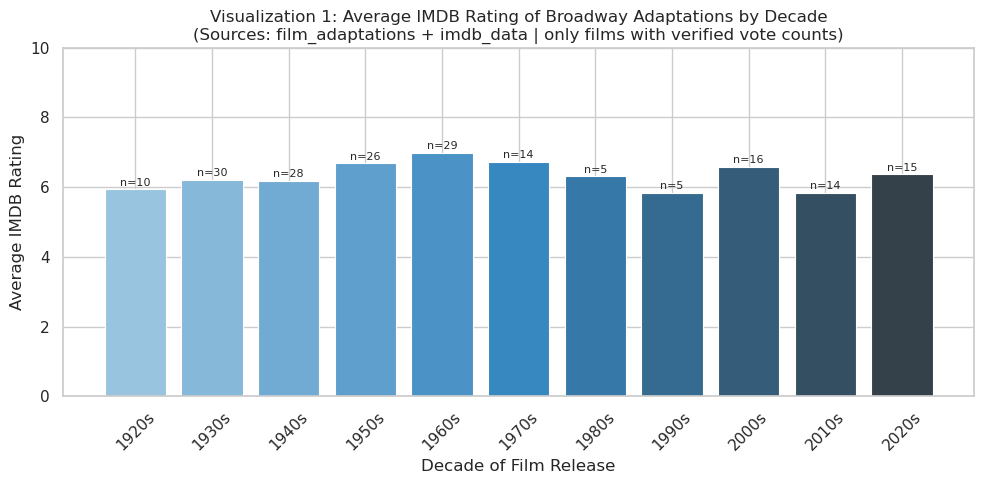

In [300]:
# Visualization 1: Average IMDB Rating by Decade of Film Release
# Sources: film_adaptations + imdb_data
# Only includes films with real vote counts to avoid median-fill distortion.

viz1_sql = """
SELECT imdb.Decade,
       ROUND(AVG(imdb.IMDB_Rating), 2) AS Avg_Rating,
       COUNT(*) AS Film_Count
FROM film_adaptations fa
JOIN imdb_data imdb
    ON LOWER(TRIM(fa.Film_Title)) = LOWER(TRIM(imdb.Title))
   AND fa.Film_Year = imdb.Year
WHERE imdb.Vote_Count IS NOT NULL
  AND fa.Film_Year > fa.Musical_Year
  AND imdb.Decade NOT IN ('Unknown')
GROUP BY imdb.Decade
ORDER BY imdb.Decade
"""
viz1_df = pd.read_sql(viz1_sql, conn)

fig, ax = plt.subplots(figsize=(10, 5))
colors = sns.color_palette('Blues_d', len(viz1_df))
bars = ax.bar(viz1_df['Decade'], viz1_df['Avg_Rating'], color=colors, edgecolor='white', linewidth=0.8)
ax.set_ylim(0, 10)
ax.set_xlabel('Decade of Film Release')
ax.set_ylabel('Average IMDB Rating')
ax.set_title('Visualization 1: Average IMDB Rating of Broadway Adaptations by Decade\n'
             '(Sources: film_adaptations + imdb_data | only films with verified vote counts)')
for bar, row in zip(bars, viz1_df.itertuples()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
            f'n={row.Film_Count}', ha='center', fontsize=8)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

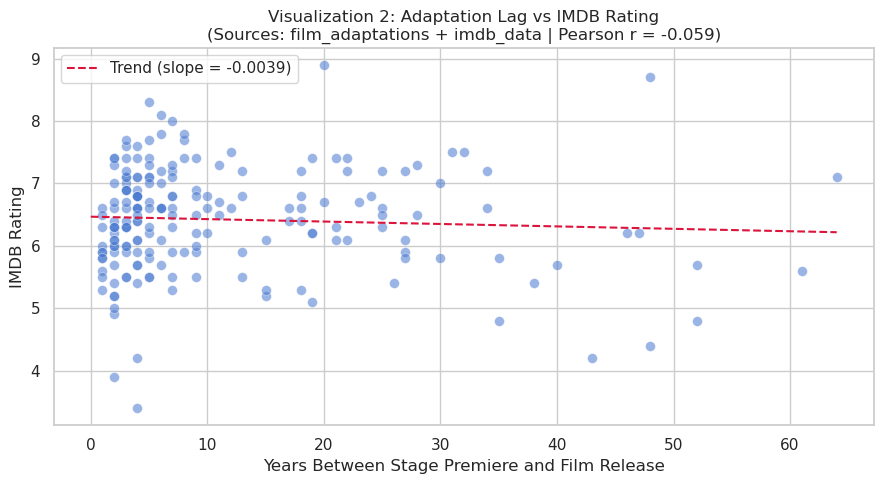

In [301]:
# Visualization 2: Years Until Film Adaptation vs IMDB Rating
# Sources: film_adaptations + imdb_data
# Tests whether faster or slower adaptation correlates with film quality.

viz2_df = merged_df[
    merged_df['Vote_Count'].notna() &
    merged_df['Years_Until_Adaptation'].notna() &
    (merged_df['Years_Until_Adaptation'] >= 0)
].copy()

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(viz2_df['Years_Until_Adaptation'].astype(float),
           viz2_df['IMDB_Rating'].astype(float),
           alpha=0.55, edgecolors='white', linewidth=0.4, s=50,
           color=sns.color_palette('muted')[0])
z = np.polyfit(viz2_df['Years_Until_Adaptation'].astype(float),
               viz2_df['IMDB_Rating'].astype(float), 1)
p_fn = np.poly1d(z)
x_line = np.linspace(0, float(viz2_df['Years_Until_Adaptation'].max()), 200)
ax.plot(x_line, p_fn(x_line), color='crimson', linewidth=1.5, linestyle='--',
        label=f'Trend (slope = {z[0]:.4f})')
corr2 = viz2_df['Years_Until_Adaptation'].astype(float).corr(viz2_df['IMDB_Rating'].astype(float))
ax.set_xlabel('Years Between Stage Premiere and Film Release')
ax.set_ylabel('IMDB Rating')
ax.set_title('Visualization 2: Adaptation Lag vs IMDB Rating\n'
             f'(Sources: film_adaptations + imdb_data | Pearson r = {corr2:.3f})')
ax.legend()
plt.tight_layout()
plt.show()

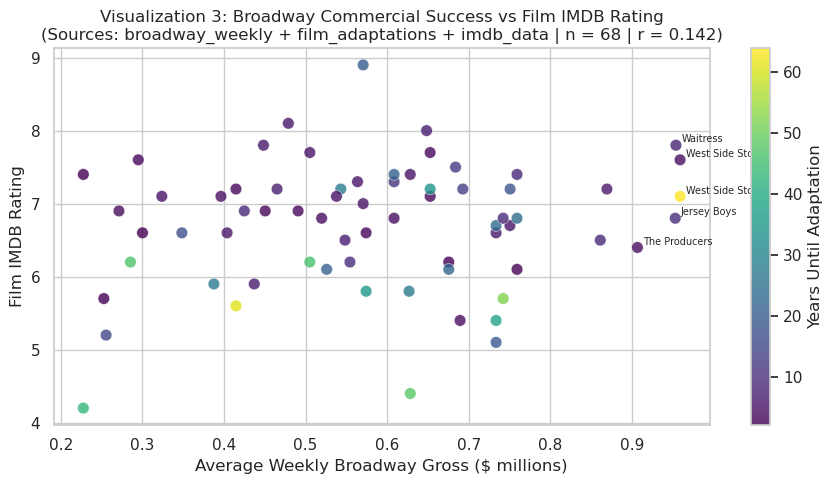

In [ ]:
# Visualization 3: Broadway Average Weekly Gross vs Film IMDB Rating
# Sources: broadway_weekly + film_adaptations + imdb_data
# Tests whether Broadway commercial success predicts film adaptation quality.
# Color encodes years until adaptation; top 5 grossing shows are labeled.

viz3_df = merged_df[
    merged_df['Vote_Count'].notna() &
    merged_df['Avg_Weekly_Gross'].notna()
].copy()

fig, ax = plt.subplots(figsize=(9, 5))
sc = ax.scatter(viz3_df['Avg_Weekly_Gross'] / 1e6, viz3_df['IMDB_Rating'],
                c=viz3_df['Years_Until_Adaptation'].astype(float),
                cmap='viridis', alpha=0.8, edgecolors='white', linewidth=0.4, s=70)
plt.colorbar(sc, ax=ax, label='Years Until Adaptation')
for _, row in viz3_df.nlargest(5, 'Avg_Weekly_Gross').iterrows():
    ax.annotate(row['Musical'],
                (row['Avg_Weekly_Gross'] / 1e6, row['IMDB_Rating']),
                fontsize=7, xytext=(4, 2), textcoords='offset points')
corr3 = viz3_df['Avg_Weekly_Gross'].corr(viz3_df['IMDB_Rating'])
ax.set_xlabel('Average Weekly Broadway Gross ( millions)')
ax.set_ylabel('Film IMDB Rating')
ax.set_title('Visualization 3: Broadway Commercial Success vs Film IMDB Rating\n'
             f'(Sources: broadway_weekly + film_adaptations + imdb_data | n = {len(viz3_df)} | r = {corr3:.3f})')
plt.tight_layout()
plt.show()

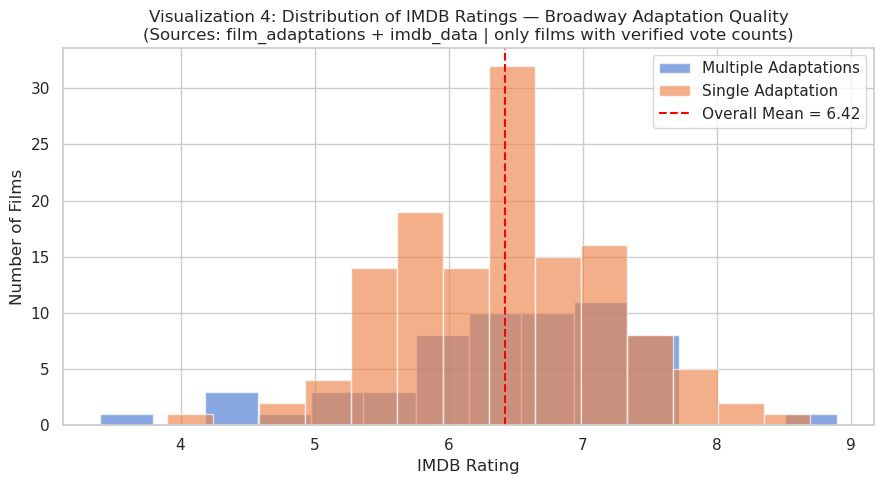

In [303]:
# Visualization 4: Distribution of Film IMDB Ratings — Single vs Multiple Adaptations
# Sources: film_adaptations + imdb_data
# Compares rating distributions for one-time vs repeatedly adapted musicals.

viz4_df = merged_df[merged_df['Vote_Count'].notna()].copy()
viz4_df['Adaptation_Type'] = viz4_df['Multiple_Adaptations'].astype(bool).map(
    {True: 'Multiple Adaptations', False: 'Single Adaptation'})

fig, ax = plt.subplots(figsize=(9, 5))
for label, grp in viz4_df.groupby('Adaptation_Type'):
    ax.hist(grp['IMDB_Rating'], bins=14, alpha=0.65, label=label, edgecolor='white')
mean_val = viz4_df['IMDB_Rating'].mean()
ax.axvline(mean_val, color='red', linestyle='--', linewidth=1.5,
           label=f'Overall Mean = {mean_val:.2f}')
ax.set_xlabel('IMDB Rating')
ax.set_ylabel('Number of Films')
ax.set_title('Visualization 4: Distribution of IMDB Ratings — Broadway Adaptation Quality\n'
             '(Sources: film_adaptations + imdb_data | only films with verified vote counts)')
ax.legend()
plt.tight_layout()
plt.show()

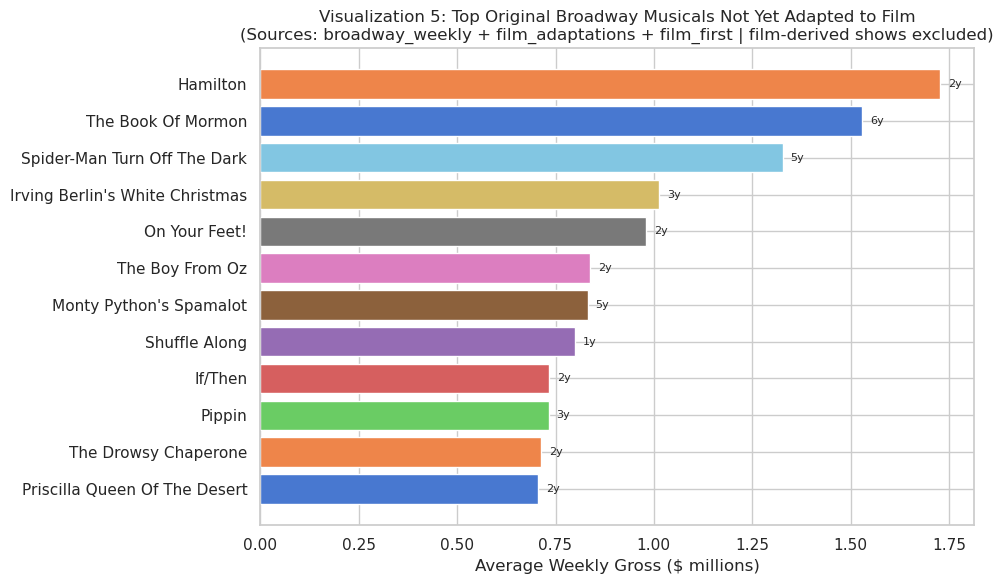


Top original unfilmed Broadway musicals (>=50 performances in dataset):
                      Show_Name  Avg_Weekly_Gross  Years_On_Broadway  Total_Performances
                       Hamilton         1727366.0                  2                 428
             The Book Of Mormon         1529381.0                  6                2258
   Spider-Man Turn Off The Dark         1327538.0                  5                1066
Irving Berlin's White Christmas         1014183.0                  3                 104
                  On Your Feet!          981193.0                  2                 322
                The Boy From Oz          838007.0                  2                 364
        Monty Python's Spamalot          832017.0                  5                1575
                  Shuffle Along          798655.0                  1                 100
                        If/Then          733984.0                  2                 401
                         Pippin      

In [ ]:
# Visualization 5: Top Broadway Musicals Not Yet Adapted to Film
# Sources: broadway_weekly + film_adaptations + film_first
# Ranks original unfilmed shows by average weekly gross.
# Closed-world assumption: only shows explicitly verified as original (Film_First=0)
# are included. Shows not yet checked by prior-film detection are excluded.

unfilmed_sql = """
SELECT
    bw.Show_Name,
    ROUND(AVG(bw.Gross), 0)       AS Avg_Weekly_Gross,
    COUNT(DISTINCT bw.Date_Year)  AS Years_On_Broadway,
    SUM(bw.Performances)          AS Total_Performances
FROM broadway_weekly bw
LEFT JOIN film_adaptations fa
    ON LOWER(TRIM(bw.Show_Name)) = LOWER(TRIM(fa.Musical))
LEFT JOIN film_first ff
    ON LOWER(TRIM(bw.Show_Name)) = LOWER(TRIM(ff.Show_Name))
WHERE fa.Musical IS NULL
  AND ff.Film_First = 0
GROUP BY bw.Show_Name
HAVING Total_Performances >= 50
ORDER BY Avg_Weekly_Gross DESC
LIMIT 12
"""
unfilmed_df = pd.read_sql(unfilmed_sql, conn)
unfilmed_sorted = unfilmed_df.sort_values('Avg_Weekly_Gross', ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 6))
palette = sns.color_palette('muted', len(unfilmed_sorted))
bars = ax.barh(unfilmed_sorted['Show_Name'], unfilmed_sorted['Avg_Weekly_Gross'] / 1e6,
               color=palette, edgecolor='white')
for bar, row in zip(bars, unfilmed_sorted.itertuples()):
    ax.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height() / 2,
            f'{int(row.Years_On_Broadway)}y', va='center', fontsize=8)
ax.set_xlabel('Average Weekly Gross ( millions)')
ax.set_title('Visualization 5: Top Original Broadway Musicals Not Yet Adapted to Film\n'
             '(Sources: broadway_weekly + film_adaptations + film_first | film-derived shows excluded)')
plt.tight_layout()
plt.show()
print('\nTop original unfilmed Broadway musicals (>=50 performances in dataset):')
print(unfilmed_df[['Show_Name', 'Avg_Weekly_Gross', 'Years_On_Broadway', 'Total_Performances']].to_string(index=False))

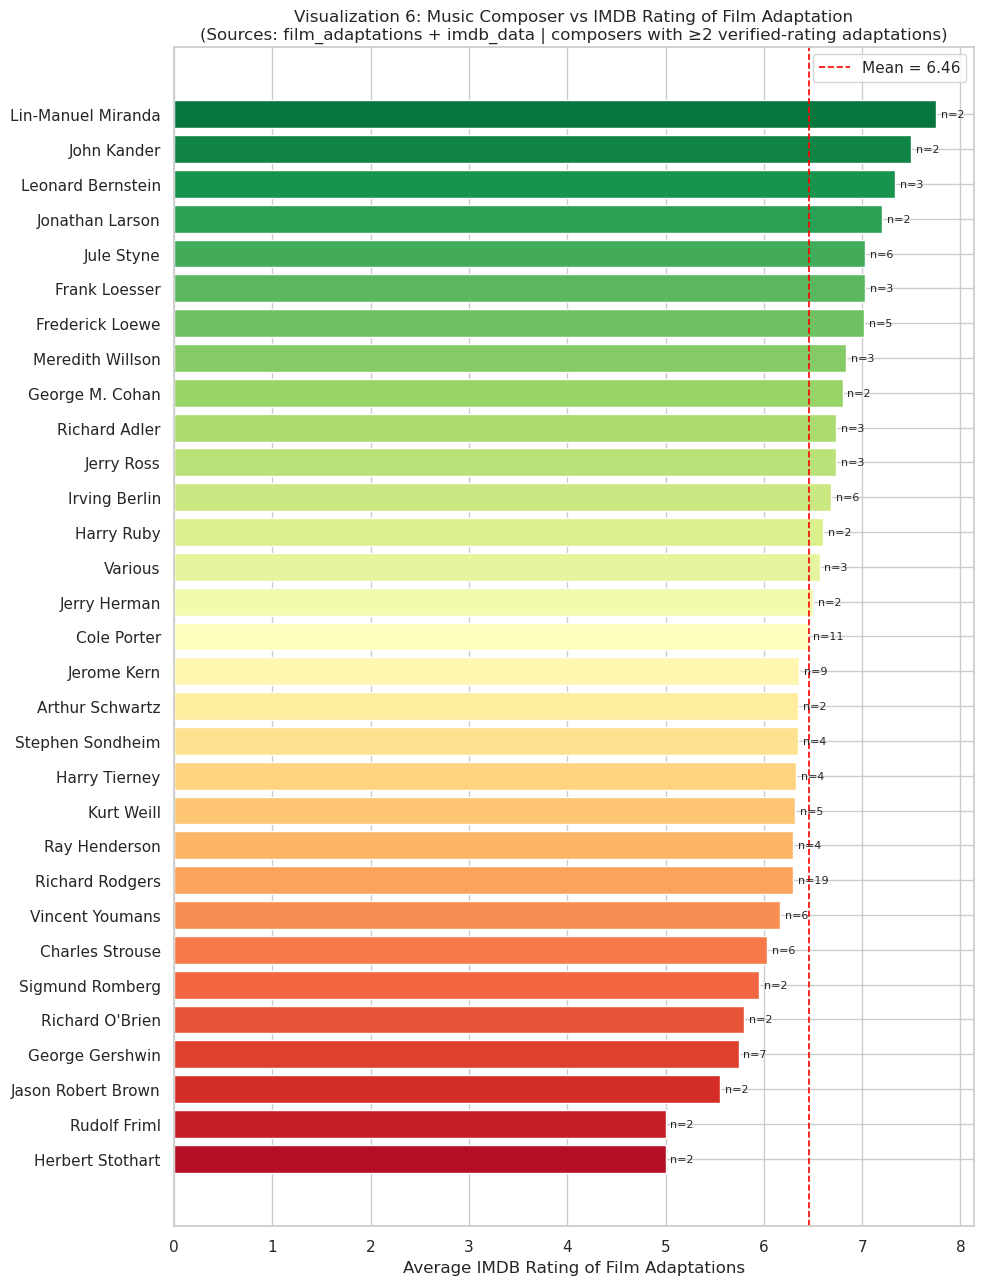


Composers with ≥2 verified adaptations: 31
          Composer  Avg_Rating  Adaptation_Count
Lin-Manuel Miranda    7.750000                 2
       John Kander    7.500000                 2
 Leonard Bernstein    7.333333                 3
   Jonathan Larson    7.200000                 2
        Jule Styne    7.033333                 6
     Frank Loesser    7.033333                 3
   Frederick Loewe    7.020000                 5
  Meredith Willson    6.833333                 3
   George M. Cohan    6.800000                 2
        Jerry Ross    6.733333                 3
     Richard Adler    6.733333                 3
     Irving Berlin    6.683333                 6
        Harry Ruby    6.600000                 2
           Various    6.566667                 3
      Jerry Herman    6.500000                 2
       Cole Porter    6.445455                11
       Jerome Kern    6.355556                 9
   Arthur Schwartz    6.350000                 2
  Stephen Sondheim    6.3

In [305]:
# Visualization 6: Music Composer vs IMDB Rating of Film Adaptation
# Sources: film_adaptations + imdb_data
# Identifies whether certain composers' stage works consistently produce better film adaptations.
# Multiple composers per show are split and counted individually.
# Only composers with ≥2 verified-rating adaptations are shown.

writer_sql = """
SELECT fa.Music_Composer, imdb.IMDB_Rating, imdb.Vote_Count
FROM film_adaptations fa
LEFT JOIN imdb_data imdb
    ON LOWER(TRIM(fa.Film_Title)) = LOWER(TRIM(imdb.Title))
   AND fa.Film_Year = imdb.Year
WHERE fa.Film_Year > fa.Musical_Year
  AND fa.Film_Year IS NOT NULL
  AND imdb.Vote_Count IS NOT NULL
  AND fa.Music_Composer IS NOT NULL
"""
writer_raw = pd.read_sql(writer_sql, conn)
writer_raw['Composer_List'] = writer_raw['Music_Composer'].str.split(', ')
writer_exploded = writer_raw.explode('Composer_List').copy()
writer_exploded['Composer_List'] = writer_exploded['Composer_List'].str.strip()
writer_exploded = writer_exploded[writer_exploded['Composer_List'].str.len() > 0]

comp_stats = (writer_exploded
    .groupby('Composer_List')
    .agg(Avg_Rating=('IMDB_Rating', 'mean'), Adaptation_Count=('IMDB_Rating', 'count'))
    .reset_index()
    .rename(columns={'Composer_List': 'Composer'})
)
comp_stats = comp_stats[comp_stats['Adaptation_Count'] >= 2].sort_values('Avg_Rating', ascending=True)

fig, ax = plt.subplots(figsize=(10, max(5, len(comp_stats) * 0.42)))
palette = sns.color_palette('RdYlGn', len(comp_stats))
bars = ax.barh(comp_stats['Composer'], comp_stats['Avg_Rating'], color=palette, edgecolor='white')
for bar, row in zip(bars, comp_stats.itertuples()):
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height() / 2,
            f'n={row.Adaptation_Count}', va='center', fontsize=8)
overall_mean = comp_stats['Avg_Rating'].mean()
ax.axvline(overall_mean, color='red', linestyle='--', linewidth=1.2,
           label=f'Mean = {overall_mean:.2f}')
ax.set_xlabel('Average IMDB Rating of Film Adaptations')
ax.set_title('Visualization 6: Music Composer vs IMDB Rating of Film Adaptation\n'
             '(Sources: film_adaptations + imdb_data | composers with ≥2 verified-rating adaptations)')
ax.legend()
plt.tight_layout()
plt.show()
print(f"\nComposers with ≥2 verified adaptations: {len(comp_stats)}")
print(comp_stats.sort_values('Avg_Rating', ascending=False).to_string(index=False))

/tmp/ipykernel_1286309/2892856978.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(groups,


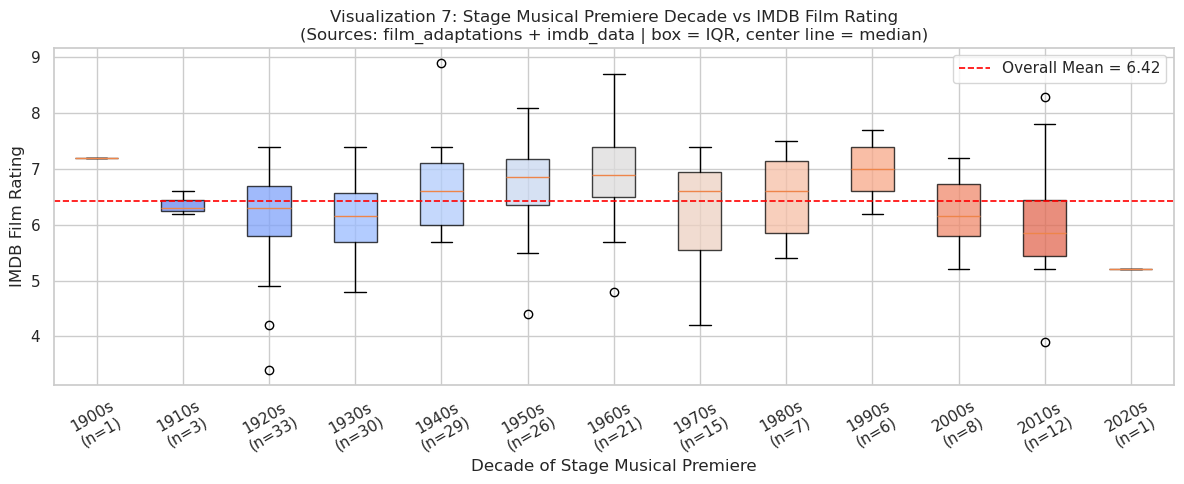

In [306]:
# Visualization 7: Stage Musical Premiere Decade vs Film IMDB Rating
# Sources: film_adaptations + imdb_data (via merged_df)
# Shows whether musicals from certain eras produce better-received film adaptations.
# Note: this uses the STAGE premiere decade, not the film release decade (shown in Viz 1).

viz7_df = merged_df[
    merged_df['Vote_Count'].notna() &
    merged_df['Musical_Year'].notna()
].copy()
viz7_df['Musical_Decade'] = ((viz7_df['Musical_Year'].astype(float) // 10) * 10).astype(int).astype(str) + 's'

decade_order = sorted(viz7_df['Musical_Decade'].unique())
groups = [viz7_df[viz7_df['Musical_Decade'] == d]['IMDB_Rating'].values for d in decade_order]
counts = [len(g) for g in groups]

fig, ax = plt.subplots(figsize=(12, 5))
bp = ax.boxplot(groups,
                labels=[f"{d}\n(n={c})" for d, c in zip(decade_order, counts)],
                patch_artist=True, notch=False)
palette = sns.color_palette('coolwarm', len(decade_order))
for patch, color in zip(bp['boxes'], palette):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
overall_mean = viz7_df['IMDB_Rating'].mean()
ax.axhline(overall_mean, color='red', linestyle='--', linewidth=1.2,
           label=f'Overall Mean = {overall_mean:.2f}')
ax.set_xlabel('Decade of Stage Musical Premiere')
ax.set_ylabel('IMDB Film Rating')
ax.set_title('Visualization 7: Stage Musical Premiere Decade vs IMDB Film Rating\n'
             '(Sources: film_adaptations + imdb_data | box = IQR, center line = median)')
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

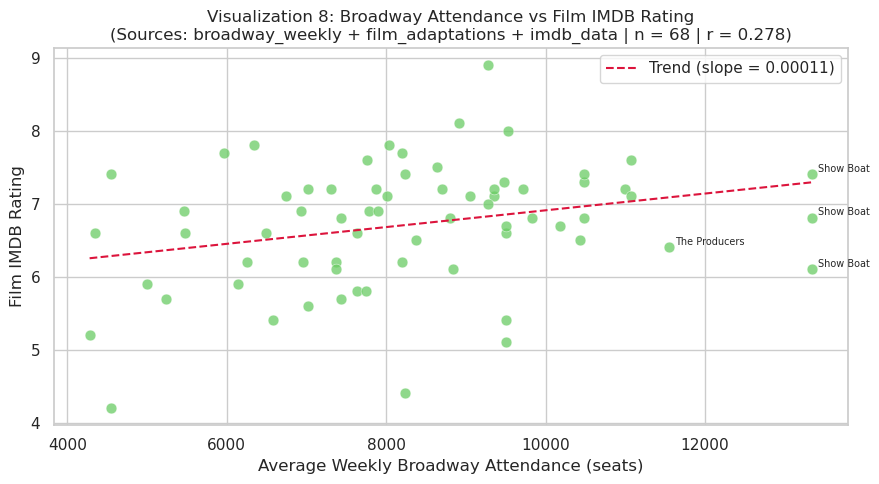

In [307]:
# Visualization 8: Broadway Average Attendance vs Film IMDB Rating
# Sources: broadway_weekly + film_adaptations + imdb_data
# Tests whether higher seat demand for the stage show predicts better film quality.
# Attendance measures how full the theater was (seats), distinct from gross (revenue).

viz8_df = merged_df[
    merged_df['Vote_Count'].notna() &
    merged_df['Avg_Attendance'].notna()
].copy()

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(viz8_df['Avg_Attendance'].astype(float), viz8_df['IMDB_Rating'].astype(float),
           alpha=0.75, edgecolors='white', linewidth=0.4, s=60,
           color=sns.color_palette('muted')[2])
z8 = np.polyfit(viz8_df['Avg_Attendance'].astype(float), viz8_df['IMDB_Rating'].astype(float), 1)
p8 = np.poly1d(z8)
x8 = np.linspace(float(viz8_df['Avg_Attendance'].min()), float(viz8_df['Avg_Attendance'].max()), 200)
ax.plot(x8, p8(x8), color='crimson', linewidth=1.5, linestyle='--',
        label=f'Trend (slope = {z8[0]:.5f})')
for _, row in viz8_df.nlargest(4, 'Avg_Attendance').iterrows():
    ax.annotate(row['Musical'], (float(row['Avg_Attendance']), float(row['IMDB_Rating'])),
                fontsize=7, xytext=(4, 2), textcoords='offset points')
corr8 = viz8_df['Avg_Attendance'].astype(float).corr(viz8_df['IMDB_Rating'].astype(float))
ax.set_xlabel('Average Weekly Broadway Attendance (seats)')
ax.set_ylabel('Film IMDB Rating')
ax.set_title('Visualization 8: Broadway Attendance vs Film IMDB Rating\n'
             f'(Sources: broadway_weekly + film_adaptations + imdb_data | n = {len(viz8_df)} | r = {corr8:.3f})')
ax.legend()
plt.tight_layout()
plt.show()

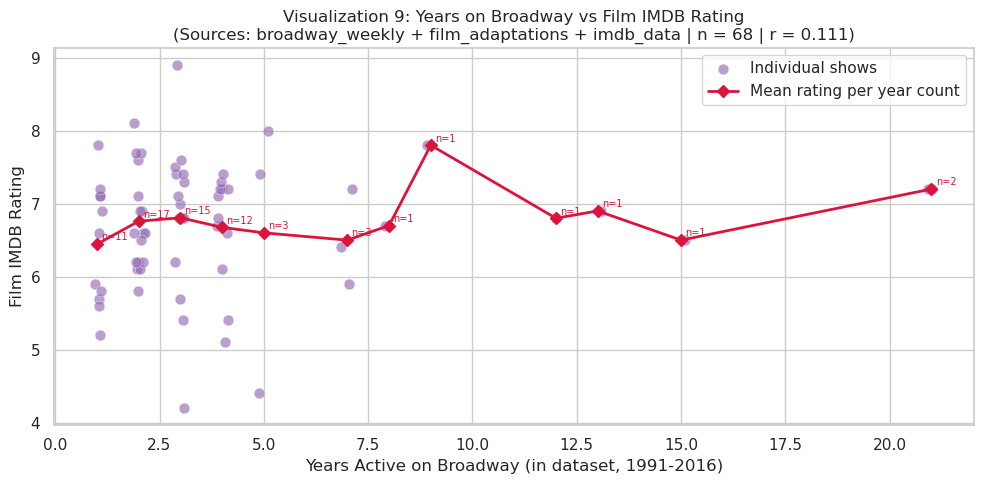

In [308]:
# Visualization 9: Years on Broadway vs Film IMDB Rating
# Sources: broadway_weekly + film_adaptations + imdb_data
# Tests whether a show's longevity on Broadway predicts film adaptation quality.
# Jitter applied horizontally to reduce overplotting on integer x-axis.
# Mean IMDB rating per year bucket overlaid as connected line.

viz9_df = merged_df[
    merged_df['Vote_Count'].notna() &
    merged_df['Years_On_Broadway'].notna()
].copy()
viz9_df['Years_On_Broadway'] = viz9_df['Years_On_Broadway'].astype(float)

rng = np.random.default_rng(42)
jitter = rng.uniform(-0.15, 0.15, size=len(viz9_df))

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(viz9_df['Years_On_Broadway'] + jitter, viz9_df['IMDB_Rating'].astype(float),
           alpha=0.65, edgecolors='white', linewidth=0.4, s=60,
           color=sns.color_palette('muted')[4], label='Individual shows')

year_means = (viz9_df.groupby('Years_On_Broadway')['IMDB_Rating']
              .agg(['mean', 'count']).reset_index())
year_means.columns = ['Years', 'Mean_Rating', 'Count']
ax.plot(year_means['Years'], year_means['Mean_Rating'],
        color='crimson', linewidth=2, marker='D', markersize=6,
        zorder=5, label='Mean rating per year count')
for _, row in year_means.iterrows():
    ax.text(row['Years'] + 0.1, row['Mean_Rating'] + 0.05,
            f"n={int(row['Count'])}", fontsize=7, color='crimson')

corr9 = viz9_df['Years_On_Broadway'].corr(viz9_df['IMDB_Rating'].astype(float))
ax.set_xlabel('Years Active on Broadway (in dataset, 1991-2016)')
ax.set_ylabel('Film IMDB Rating')
ax.set_title('Visualization 9: Years on Broadway vs Film IMDB Rating\n'
             f'(Sources: broadway_weekly + film_adaptations + imdb_data | n = {len(viz9_df)} | r = {corr9:.3f})')
ax.legend()
plt.tight_layout()
plt.show()

#### Human-Readable Merged Dataset (All Three Sources)

In [310]:
# Human-readable merged dataset spanning all three sources
print(f'Merged dataset: {merged_df.shape[0]} rows x {merged_df.shape[1]} columns')
merged_df


Merged dataset: 224 rows x 17 columns


,Musical,Musical_Year,Film_Title,Film_Year,Years_Until_Adaptation,Multiple_Adaptations,IMDB_Rating,Metacritic_Score,Vote_Count,Genres,Decade,Runtime,Poorly_Received,Avg_Attendance,Avg_Weekly_Gross,Total_Performances,Years_On_Broadway
0,13,2007,13: The Musical,2022,15,0,5.2,57.0,1266.0,Comedy | Drama | Family | Musical,2020s,1h 31m,1.0,4278.0,255528.0,96.0,1.0
1,1776,1969,1776,1972,3,0,7.6,66.5,11142.0,Drama | Family | History | Musical,1970s,2h 21m,0.0,7756.0,294996.0,325.0,2.0
2,"Alma, Where Do You Live?",1910,"Alma, Where Do You Live?",1917,7,0,6.5,66.5,NaN,Comedy,1910s,1h 00m,0.0,NaN,NaN,NaN,NaN
3,Animal Crackers,1928,Animal Crackers,1930,2,0,7.4,77.0,16197.0,Comedy | Family | Musical,1930s,1h 37m,0.0,NaN,NaN,NaN,NaN
4,Annie,1976,Annie,1982,6,1,6.6,39.0,53550.0,Comedy | Drama | Family | Musical,1980s,2h 07m,0.0,9500.0,733559.0,726.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
219,Where's Charley?,1948,Where's Charley?,1952,4,0,6.8,66.5,174.0,Comedy | Musical,1950s,1h 37m,0.0,NaN,NaN,NaN,NaN
220,Whoopee!,1928,Whoopee!,1930,2,0,6.3,66.5,1321.0,Comedy | Musical | Romance | Western,1930s,1h 33m,0.0,NaN,NaN,NaN,NaN
221,Wicked,2003,"Wicked film series:, Wicked, Wicked: For Good",2024,21,0,NaN,NaN,NaN,None,None,None,NaN,14237.0,1554441.0,5335.0,14.0
222,The Wiz,1974,The Wiz,1978,4,0,5.7,53.0,19648.0,Adventure | Family | Fantasy | Musical,1970s,2h 14m,0.0,NaN,NaN,NaN,NaN


#### Project Summary

**What changes were made to the data?** Three datasets were integrated into one analysis-ready table via SQLite. Weekly Broadway performance records (1991–2016) were aggregated per show and joined to a Wikipedia table of stage-to-film adaptations by musical name, then further joined to IMDB API film data by film title and release year. Across Milestones 2–4, transformations included: filtering for musicals only; standardizing casing and stripping whitespace; removing Wikipedia citation artifacts; extracting year values from parenthetical notation; replacing empty strings with NaN; filling missing numeric ratings with column medians; converting API list fields to pipe-delimited strings; and deriving computed columns (Years_Until_Adaptation, Decade, Poorly_Received, Multiple_Adaptations). An additional data quality step was added in Milestone 5: for each Broadway show with no matched film adaptation, the IMDB API was queried to detect prior films with a matching title. Shows where a film of the same name predates the stage debut (similarity ≥ 0.85 via SequenceMatcher, title-suffix normalization applied) were classified as film-derived and excluded from adaptation recommendations. This identified several disqualified shows such as Aladdin (1992), The Lion King (1994), A Christmas Story (1983), Kinky Boots (2005 documentary), Billy Elliot (2000), and An American in Paris (1951), ensuring Visualization 5 reflects only original stage properties that have not yet been adapted.

**Legal and regulatory guidelines:** Broadway League data is available for academic use via the CORGIS Datasets Project. Wikipedia is licensed under CC BY-SA 4.0, permitting analysis with attribution. IMDB data was obtained via an unofficial third-party aggregator API (api.imdbapi.dev); IMDb's own Terms of Service discourage automated scraping, placing academic non-commercial usage in a legal gray area.

**Risks from transformations:** Missing IMDB and Metacritic scores were filled with column medians, which may distort analysis for films missing ratings for non-random reasons such as limited theatrical releases. Name-based joins across Broadway League and Wikipedia sources use case-normalized exact string matching; slight naming discrepancies cause silent data loss. The binary "Poorly Received" flag reduces a continuous rating distribution to an oversimplified judgment that ignores era, budget, and genre context. The film-first detection step relies on a similarity threshold (0.85) and manual overrides for known false positives; edge cases (e.g., shows with generic titles or revivals whose true premiere predates the dataset window) may be misclassified.

**Assumptions:** Show names in the Broadway League dataset are assumed to be consistent enough with Wikipedia musical names to join after case normalization. Average weekly gross is assumed to be a valid proxy for commercial popularity and adaptation-worthiness. Median imputation for missing ratings assumes data is missing at random. The Broadway League dataset covers 1991–2016, so "debut year" for older shows reflects the most recent revival in that window rather than the true world premiere; this is handled via manual overrides where known.

**Credibility and ethical acquisition:** All three sources are publicly available: a nationally recognized trade association (Broadway League), a collaboratively maintained encyclopedia (Wikipedia), and a crowd-sourced film database (IMDb). No authentication was bypassed, no PII is present, and API requests used polite rate-limiting delays with results cached locally.

**Mitigating ethical implications:** All transformation steps are documented and numbered for reproducibility. The film-first detection methodology is transparent: threshold, normalization rules, and manual overrides are all hardcoded in the notebook with explanatory comments. Recommendations in Visualization 5 are framed as data-driven candidates, not production mandates. The analysis contains no demographic data, eliminating risk of disparate impact on protected groups.

**Key findings:** Nine visualizations were produced to explore factors influencing film adaptation success.

*Viz 1 — Film release decade:* Adaptations released in the 1960s earned the highest average IMDB rating (6.99, n=29), followed by the 1970s (6.73) and 1950s (6.68). The 1990s and 2010s tied for lowest (5.84 each), suggesting the golden era of Broadway-to-Hollywood translation has passed, and recent decades show declining reception.

*Viz 2 — Adaptation lag:* Essentially no correlation between years until adaptation and film quality (r=−0.059, n=192). Average wait was 11.6 years. Studios gain nothing by waiting longer.

*Viz 3 — Broadway gross vs film quality:* Very weak positive correlation (r=0.142, n=68). Commercial Broadway success is not a reliable predictor of film quality.

*Viz 4 — Single vs multiple adaptations:* Films from musicals adapted only once (mean 6.42) and those adapted multiple times (mean 6.42) rated nearly identically. Remaking a Broadway show does not improve outcomes.

*Viz 5 — Highest-grossing unfilmed shows:* After excluding shows with prior film origins, the top candidates by average weekly gross are Hamilton (1.73M), The Book of Mormon (1.53M), and Spider-Man: Turn Off the Dark (1.33M). These represent genuine original stage properties with no prior screen incarnation.

*Viz 6 — Composer signal:* The strongest factor found. Lin-Manuel Miranda leads at 7.75 average (n=2), followed by John Kander (7.50, Chicago/Cabaret), Leonard Bernstein (7.33, West Side Story), and Jonathan Larson (7.20, Rent/tick tick BOOM). Jule Styne (7.03, n=6) and Frederick Loewe (7.02, n=5) show consistent quality across large samples. George Gershwin was lowest among prolific composers (5.74, n=7), suggesting his older catalog adapts poorly.

*Viz 7 — Musical premiere decade:* Musicals that premiered in the 1950s–1960s yield the best-rated adaptations (median 6.85–6.90). Musicals from the 2010s have a median of only 5.85, likely because those properties are newer and less proven as screen material.

*Viz 8 — Broadway attendance vs film quality:* Weak positive correlation (r=0.278, n=68), the strongest relationship found across all metrics. Higher audience demand for a show is a marginally better predictor of film quality than gross revenue.

*Viz 9 — Years on Broadway vs film quality:* Very weak positive correlation (r=0.111, n=68). Long-running shows trend slightly higher, but the relationship is not reliable.

**Adaptation recommendations:** Based on commercial performance (Viz 5), composer pedigree (Viz 6), and attendance signal (Viz 8), two shows stand out as strongest candidates. **Hamilton** (1.73M average weekly gross, #1 unfilmed show; Lin-Manuel Miranda, highest composer average at 7.75) has overwhelming commercial and compositional justification — the filmed stage performance on Disney+ demonstrates audience appetite for a proper cinematic adaptation. **The Book of Mormon** (1.53M/week, 6 years on Broadway, 2,258 total performances; music by Matt Stone and Trey Parker) has the deepest sustained run in the dataset, indicating genuine long-term audience demand rather than a short box-office spike. Both shows premiered in the 2000s–2010s, a decade whose adaptations have underperformed historically, but their exceptional Broadway metrics offset that risk. Spider-Man: Turn Off the Dark (1.33M/week) ranks third by gross but carries reputational risk given its troubled production history and mixed critical reception, making it a lower-confidence recommendation despite strong box-office numbers.